**<center style="font-size:4em;">Data exploration notebook</center>**

# To-Dos:
- speichern der Grafiken in einem Ordner mit einer bestimmten Namenskonvention um nicht unzählige Kopien zu haben
- Zellen umbauen sodass die Importe immer da sind wo sie auch gebraucht werden
- Berechnen von sby_need aus calls auch in Funktion auslagern, um Copy-Paste zu vermeiden
- Prediction-Teil ggf auslagern in eine andere Datei

# Initialization

## Loading data

In [80]:
import pandas as pd

# Load the dataset
file_path = '../../data/raw/sickness_table.csv'

df = pd.read_csv(file_path, index_col=0)

In [81]:
df.dtypes

date         object
n_sick        int64
calls       float64
n_duty        int64
n_sby         int64
sby_need    float64
dafted      float64
dtype: object

## Initial data adaptions

In [82]:
# Convert date string column to datetime column
df['date'] = pd.to_datetime(df['date'])

# Add numeric date 
df['unix_ts_date'] = df['date'].astype(int) // 10**9

# Make date to index 
df.set_index('date', inplace=True)

# Set daily frequency
df = df.asfreq('d')

# Correlation matrix of data

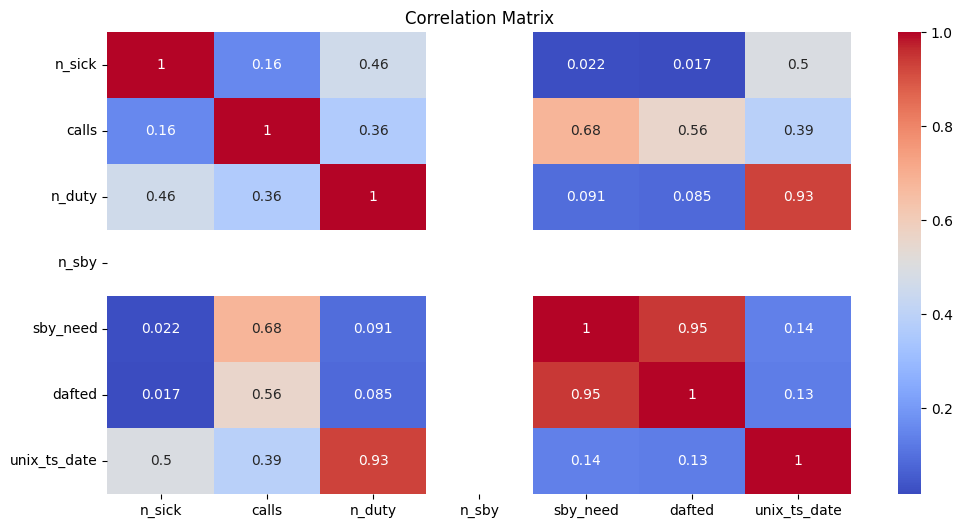

In [83]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

# Plot all columns over time

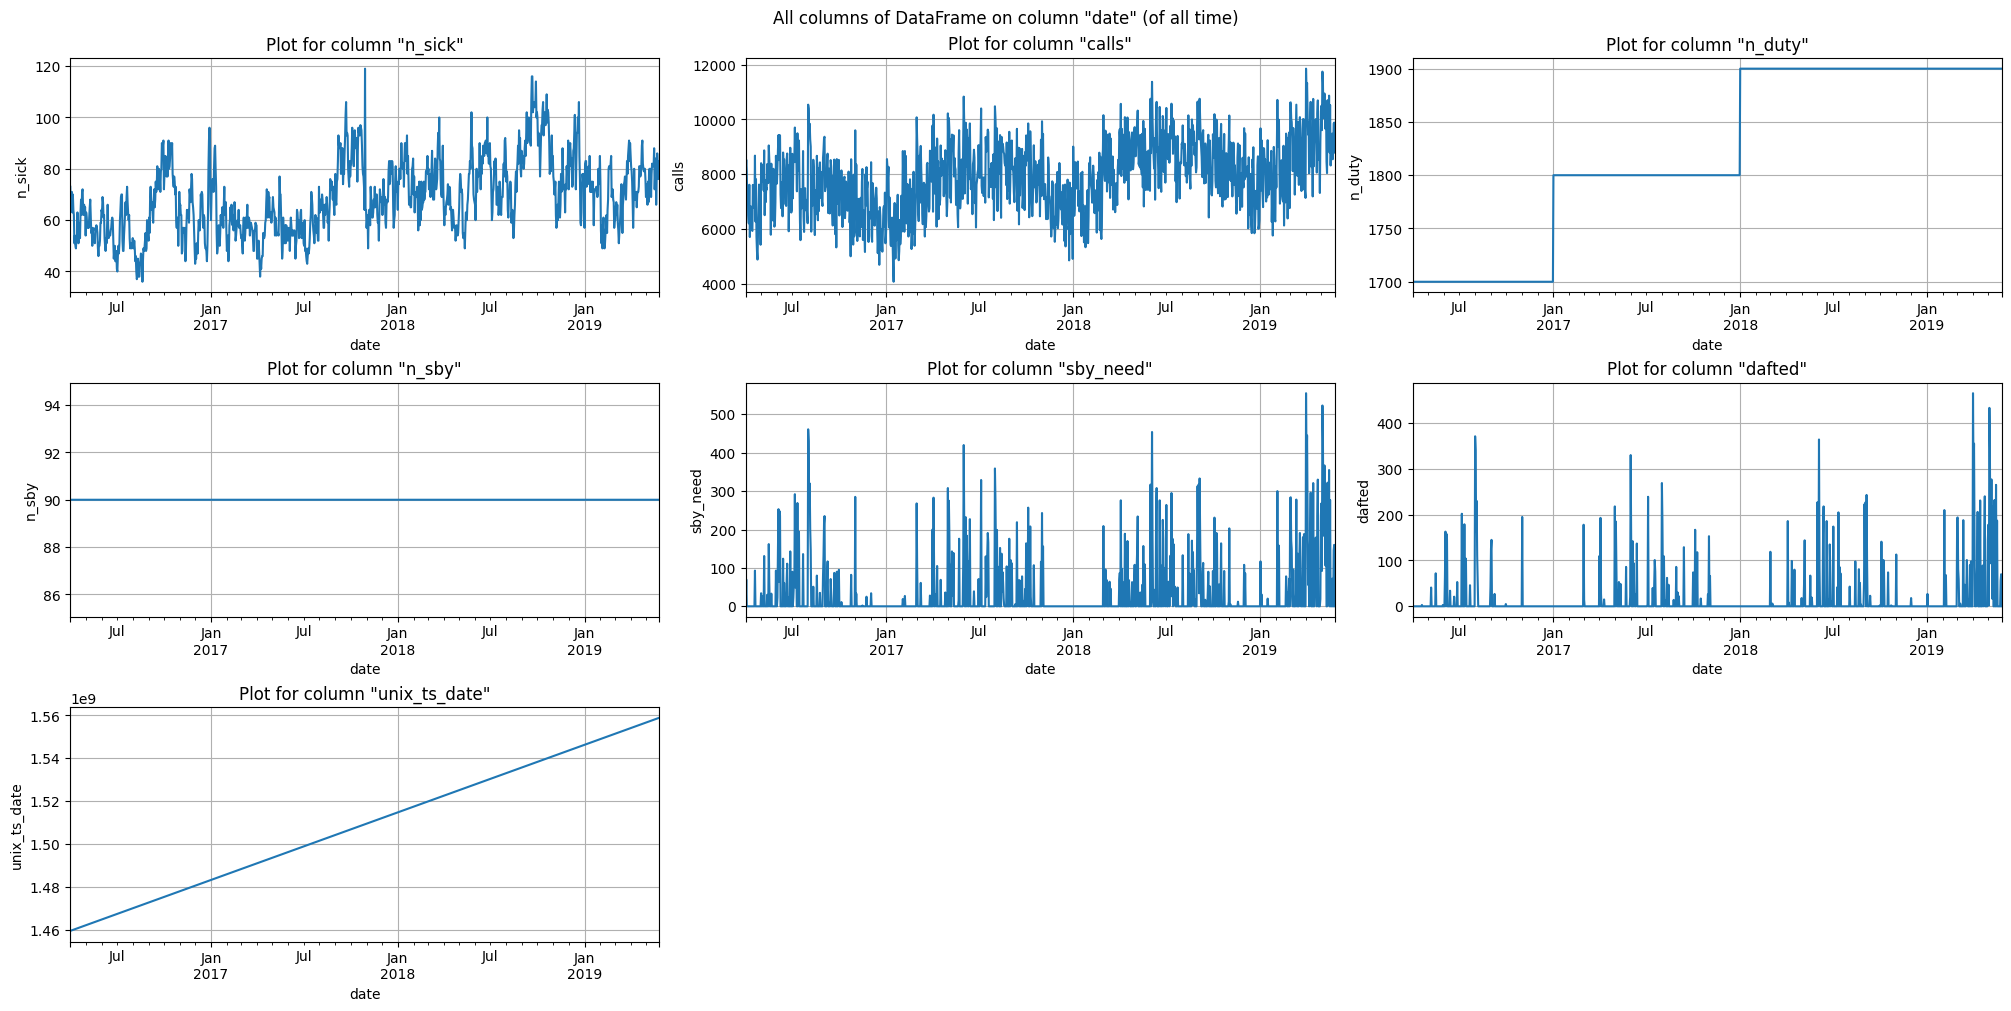

In [84]:
import math
from typing import List, Optional

def plot_columns_on_index_in_subplots(df : pd.DataFrame, columns: Optional[List[str]] = None, annotation: str = "") -> None:

    if columns is None:
        columns = df.columns

    # number of columns in datafram
    num_columns = len(columns)

    # number of rows and columns for the subplots
    num_rows = math.ceil(math.sqrt(num_columns))
    num_cols = math.ceil(num_columns / num_rows)

    # Create subplots
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(20, 10), constrained_layout=True)
    fig.suptitle(f'All columns of DataFrame on column "{df.index.name}"' + (f" ({annotation})" if annotation else ""), fontsize=12)

    # Plots für jede Spalte erstellen
    for i, column in enumerate(columns):
        row = i // num_cols
        col = i % num_cols
        ax = axes[row, col]
        df[column].plot(ax=ax, title=f'Plot for column "{column}"')
        ax.set_xlabel(df.index.name)
        ax.set_ylabel(column)
        ax.grid()

    # Leere Subplots entfernen
    for j in range(i + 1, num_rows * num_cols):
        fig.delaxes(axes.flatten()[j])

    plt.show()

plot_columns_on_index_in_subplots(df, annotation="of all time")

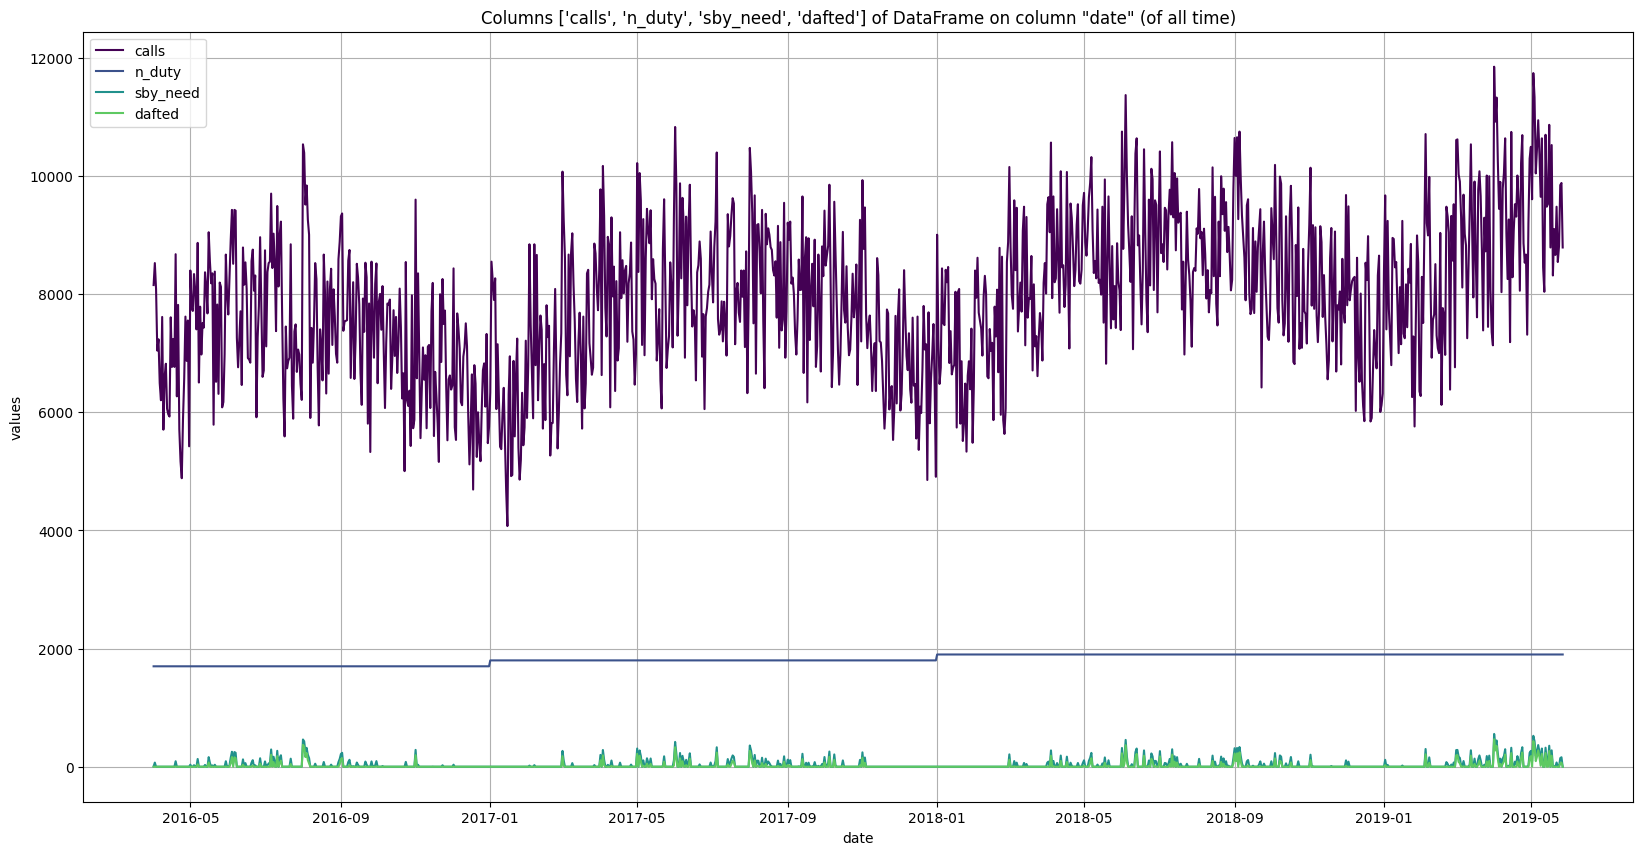

In [85]:
def plot_columns_on_index(df: pd.DataFrame, columns: Optional[List[str]] = None, annotation: str = "") -> None:
    if columns is None:
        columns = df.columns
    
    plt.figure(figsize=(20, 10))
    
    num_columns = len(columns)
    color_map = plt.get_cmap('viridis')
    
    for i, column in enumerate(columns):
        if column in df.columns:
            color = color_map(i / num_columns)
            plt.plot(df.index, df[column], label=column, color=color)
        else:
            print(f'Column "{column}" not found in DataFrame')
    
    plt.xlabel(df.index.name)
    plt.ylabel('values')
    plt.title(f'Columns {columns} of DataFrame on column "{df.index.name}"' + (f" ({annotation})" if annotation else ""))
    plt.legend()

    plt.grid()
    plt.show()

plot_columns_on_index(df, columns=["calls", "n_duty", "sby_need", "dafted"], annotation="of all time")


## Plot columns over one year

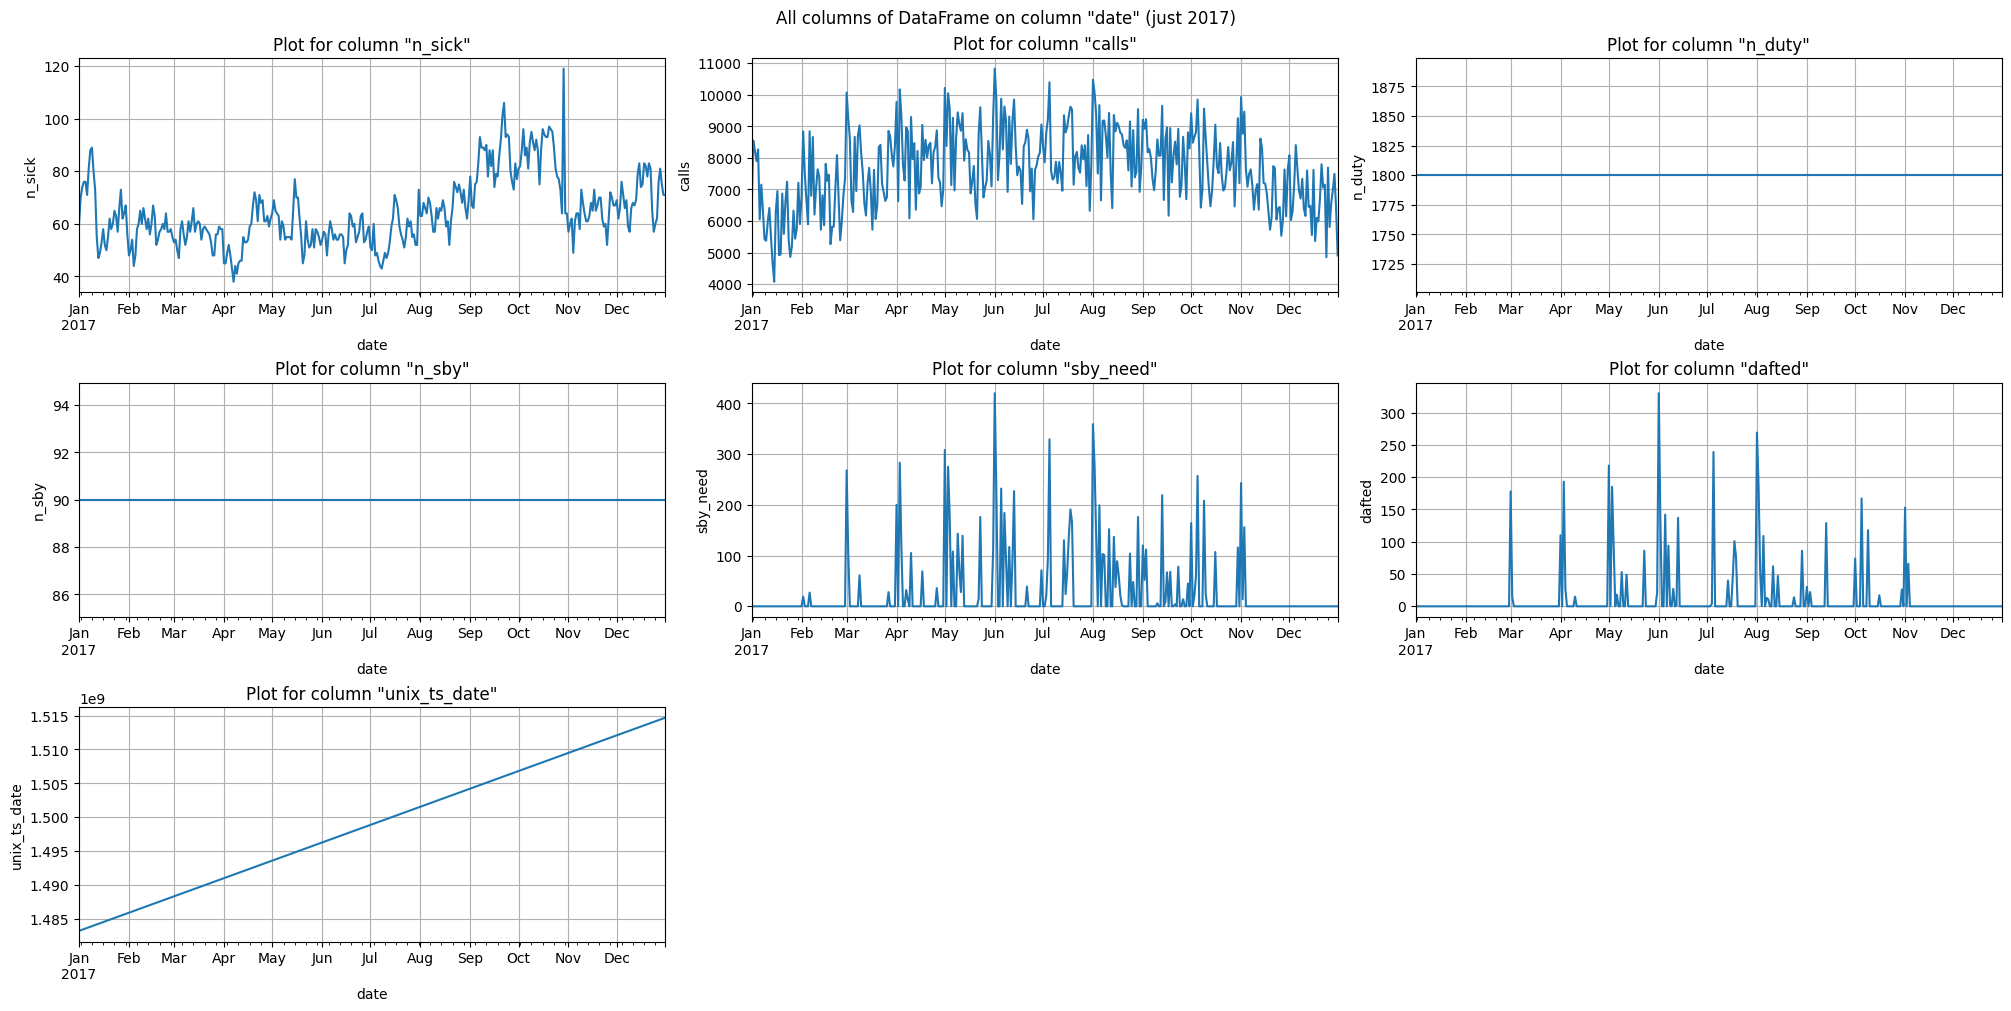

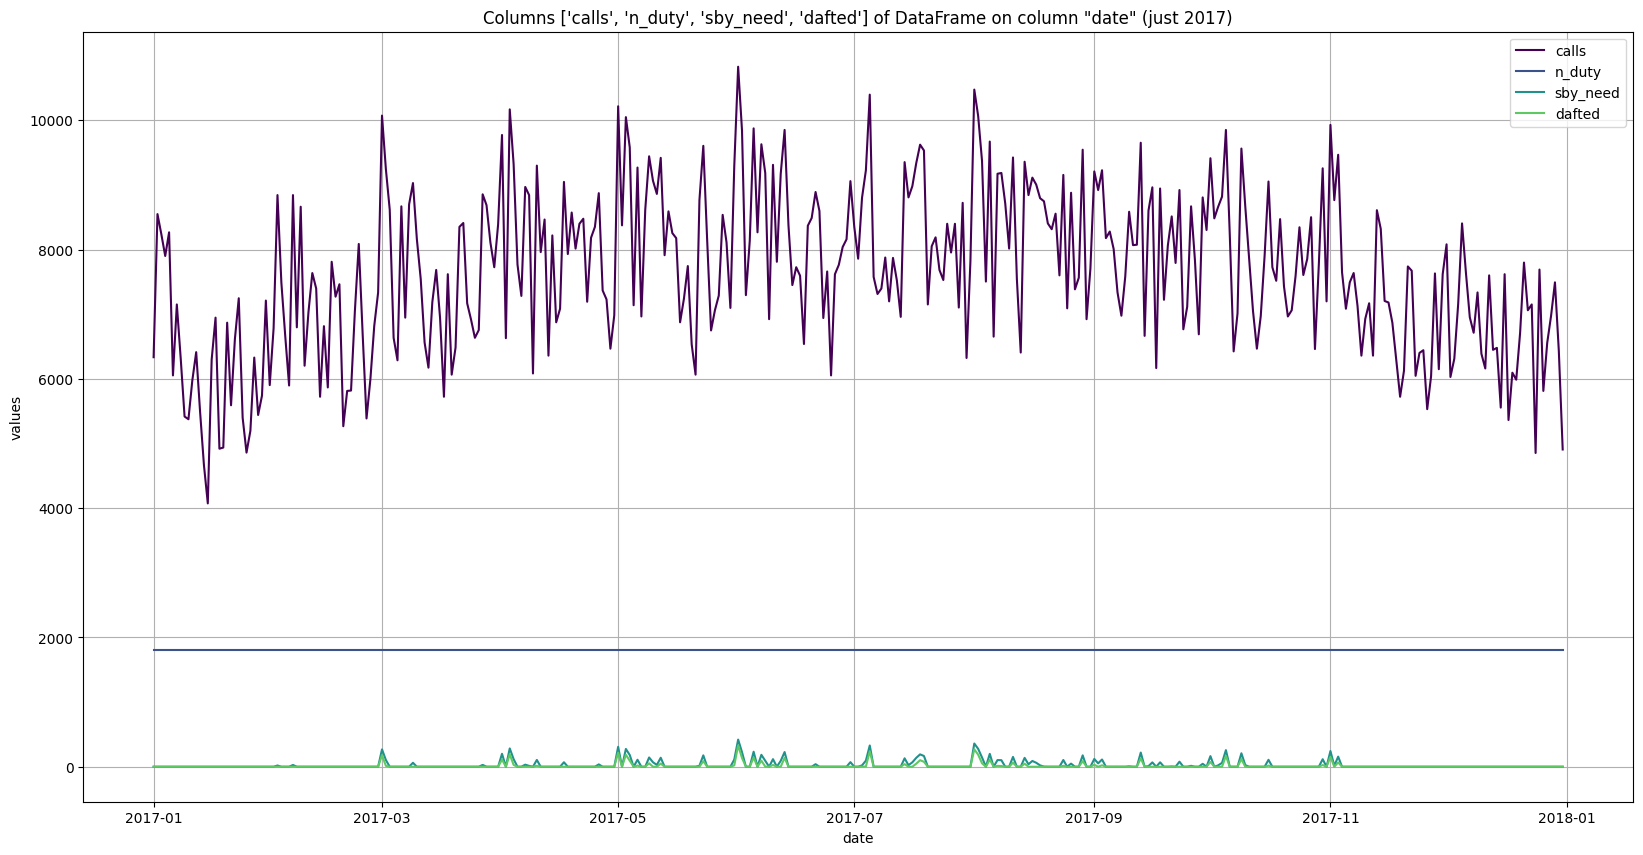

In [86]:
selected_year = 2017

one_year_df = df[df.index.year == selected_year]

plot_columns_on_index_in_subplots(one_year_df, annotation=f"just {selected_year}")
plot_columns_on_index(one_year_df, columns=["calls", "n_duty", "sby_need", "dafted"], annotation=f"just {selected_year}")

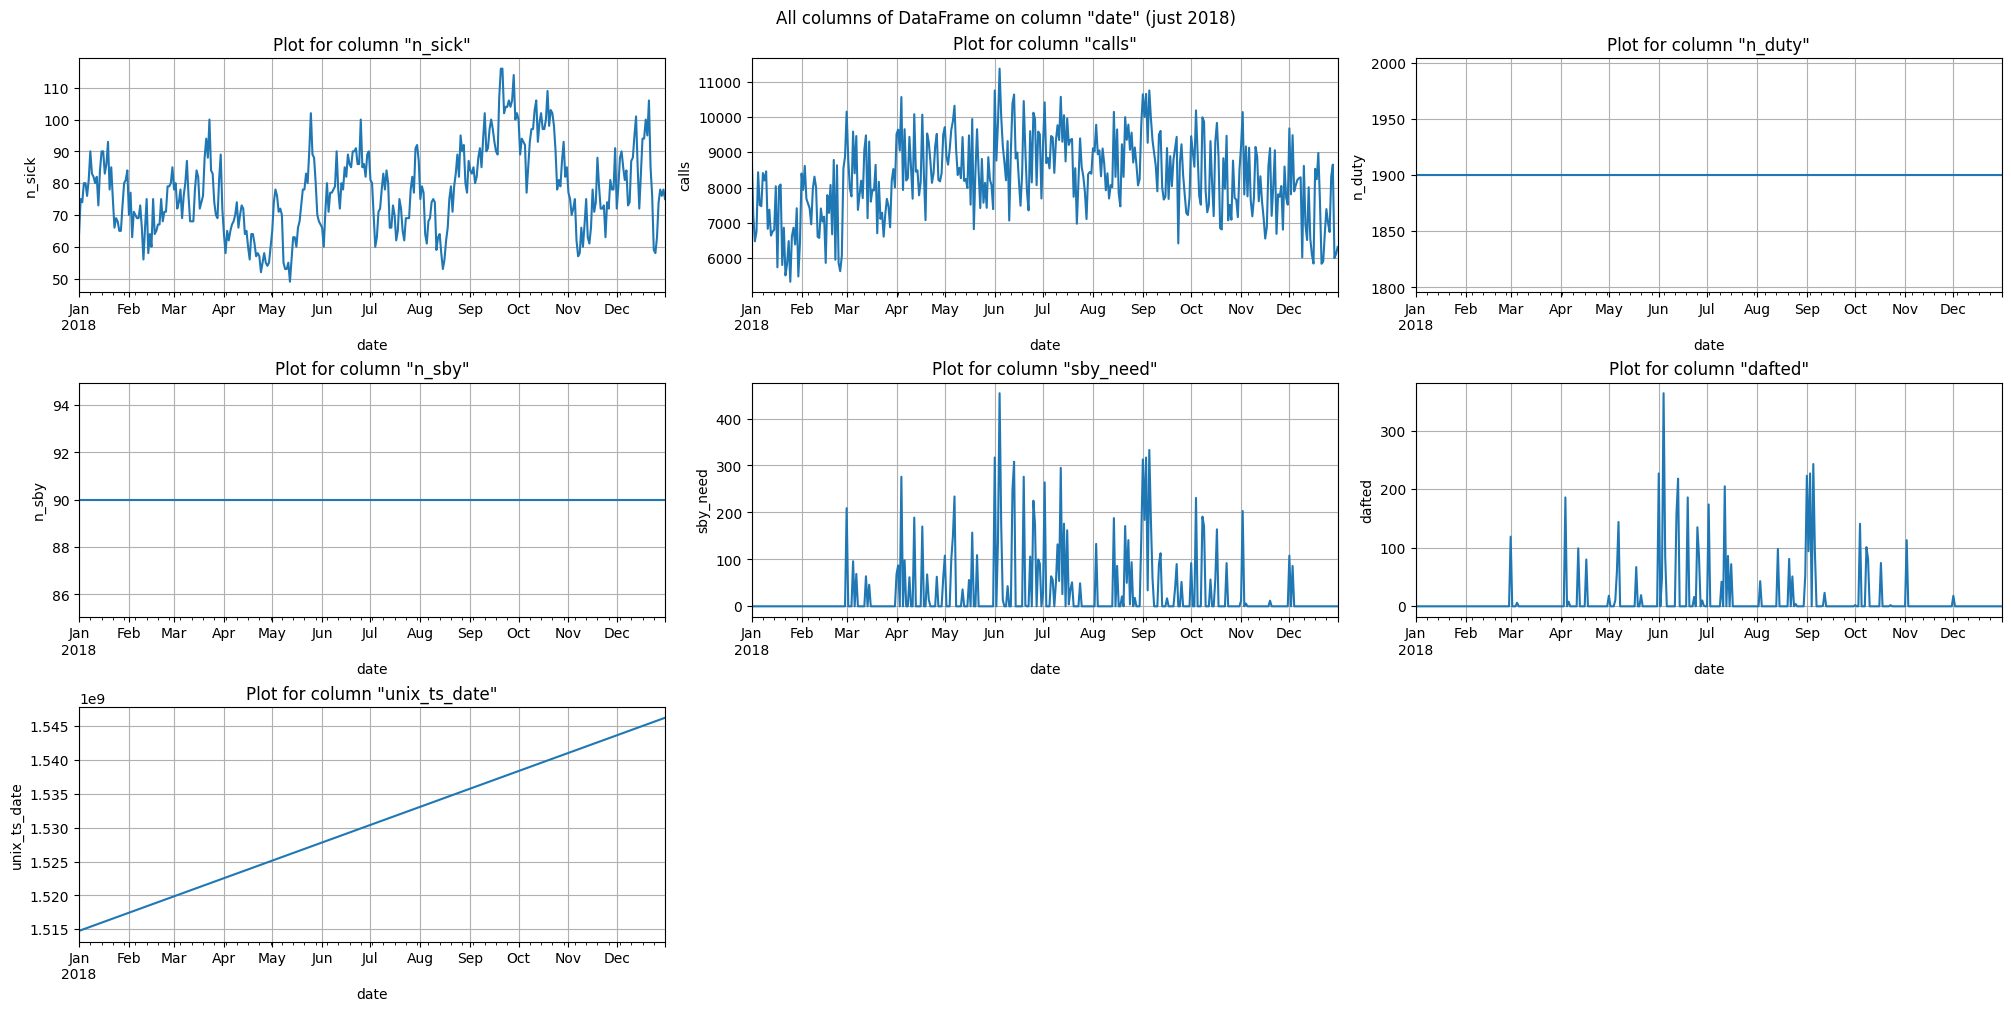

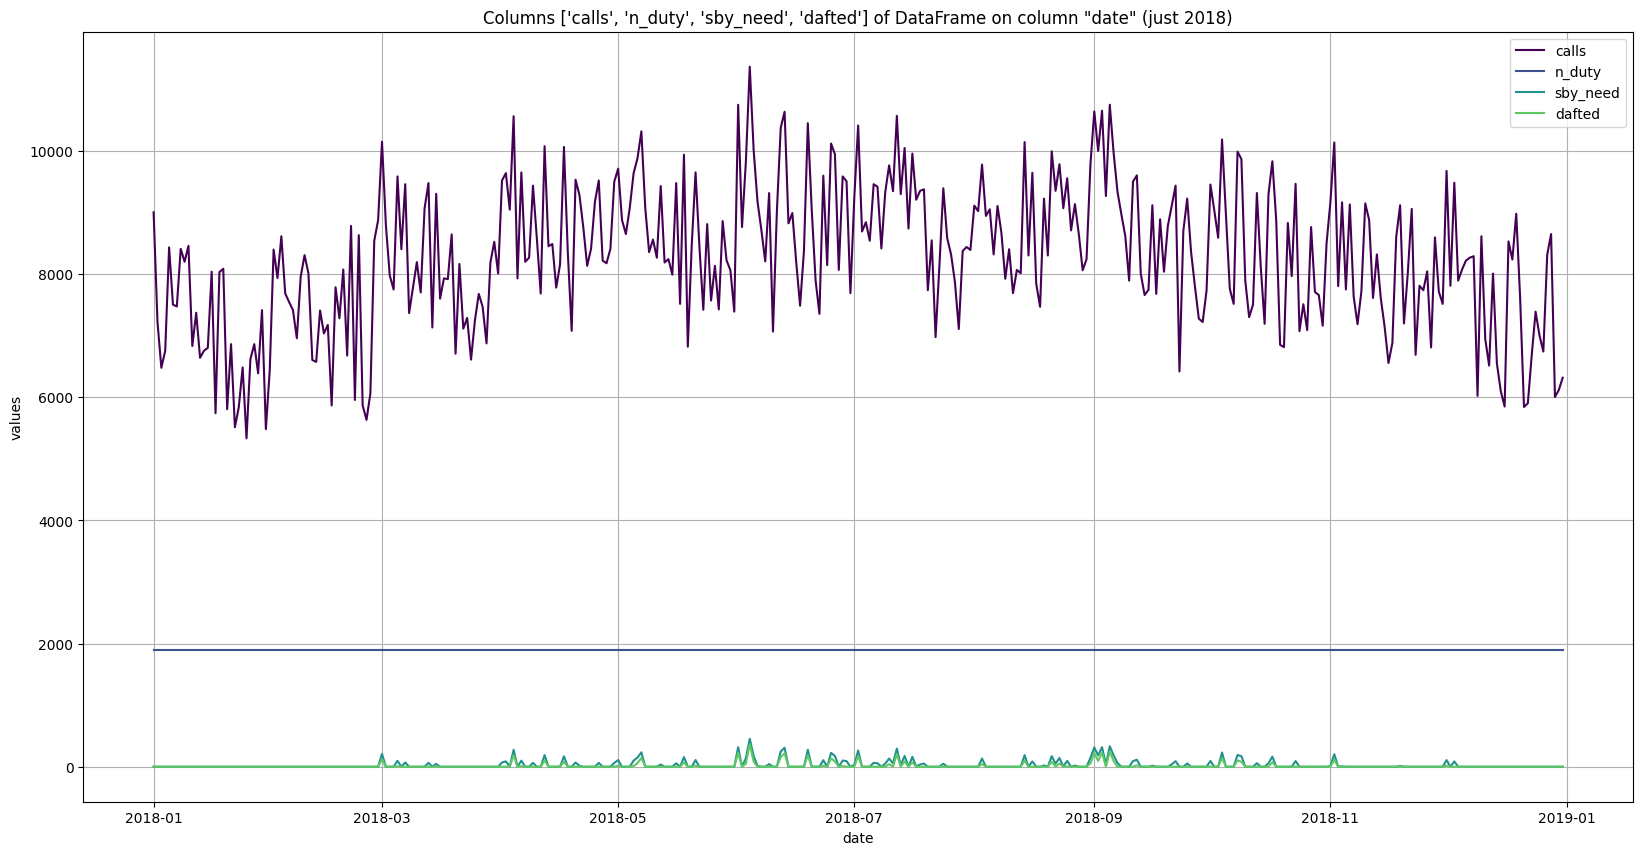

In [87]:
selected_year = 2018

one_year_df = df[df.index.year == selected_year]

plot_columns_on_index_in_subplots(one_year_df, annotation=f"just {selected_year}")
plot_columns_on_index(one_year_df, columns=["calls", "n_duty", "sby_need", "dafted"], annotation=f"just {selected_year}")

## Correlation matrix for one year

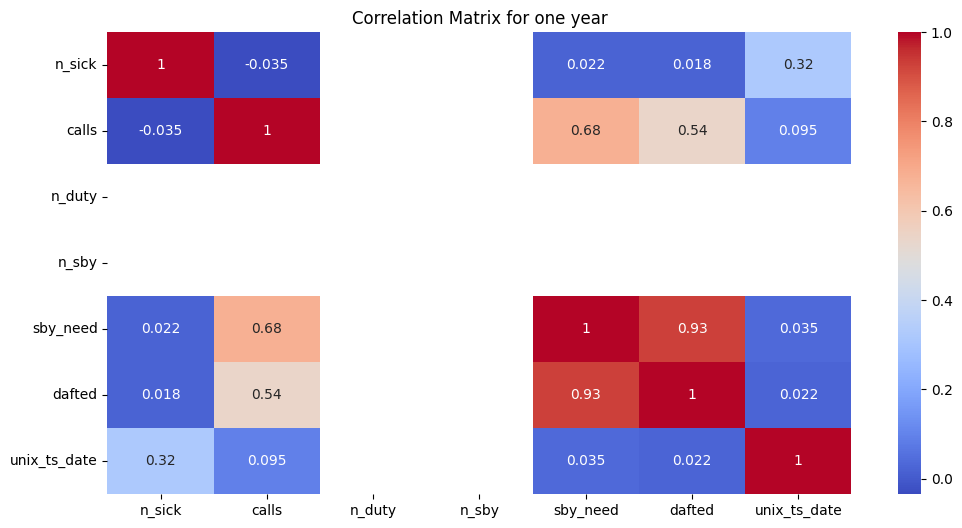

In [226]:
selected_year = 2018

one_year_df = df[df.index.year == selected_year]

plt.figure(figsize=(12, 6))
sns.heatmap(one_year_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix for one year')
plt.show()

## Findings

Erkenntnisse: 
- n_duty steigt am Anfang jeden Jahrs fix und wird nicht wieder gesenkt
- calls hat ein wiederkehrendes Muster. Es geht im Winter runter und beim Sommer hoch. Hat aber starke Ausschläge 
- ähnlich bei sby_need und logischerweise bei dafted. Im Winter nichts und sonst gelegengtlich

# Creating new columns from current columns

In [89]:
working_df = df.copy(deep=True)

# 
working_df["needed_personal"] = working_df.apply(lambda row: (row.sby_need + row.n_duty), axis=1)

working_df["personal_calculated_by_calls"] = working_df.apply(lambda row: (row.calls / 4.8), axis=1) 

##############

working_df["personal_calculated_by_calls_not_below_n_duty"] = working_df["personal_calculated_by_calls"]

# Filter from January to March
mask = (working_df["personal_calculated_by_calls"] < working_df["n_duty"])

# Add offset to filtered rows
working_df.loc[mask, 'personal_calculated_by_calls_not_below_n_duty'] = working_df.loc[mask, 'n_duty']

############

# 
working_df["sby_need_calculated_by_calls"] = working_df.apply(lambda row: row.personal_calculated_by_calls_not_below_n_duty - row.n_duty, axis=1)


#
working_df["calls_per_duty"] = working_df.apply(lambda row: row.calls / row.n_duty, axis=1)

#
working_df["call_stress"] = working_df.apply(lambda row: row.calls / (row.n_duty + row.sby_need), axis=1)

display(working_df.describe())

,n_sick,calls,n_duty,n_sby,sby_need,dafted,unix_ts_date,needed_personal,personal_calculated_by_calls,personal_calculated_by_calls_not_below_n_duty,sby_need_calculated_by_calls,calls_per_duty,call_stress
count,1152.000000,1152.000000,1152.000000,1152.0,1152.000000,1152.000000,1.152000e+03,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000
mean,68.808160,7919.531250,1820.572917,90.0,34.718750,16.335938,1.509192e+09,1855.291667,1649.902344,1857.789714,37.216797,4.347109,4.255659
std,14.293942,1290.063571,80.086953,0.0,79.694251,53.394089,2.874511e+07,117.992747,268.763244,120.808410,84.450859,0.663532,0.539535
min,36.000000,4074.000000,1700.000000,90.0,0.000000,0.000000,1.459469e+09,1700.000000,848.750000,1700.000000,0.000000,2.263333,2.263333
25%,58.000000,6978.000000,1800.000000,90.0,0.000000,0.000000,1.484330e+09,1800.000000,1453.750000,1800.000000,0.000000,3.875833,3.875833
50%,68.000000,7932.000000,1800.000000,90.0,0.000000,0.000000,1.509192e+09,1874.500000,1652.500000,1886.875000,0.000000,4.344298,4.344298
75%,78.000000,8827.500000,1900.000000,90.0,12.250000,0.000000,1.534054e+09,1900.000000,1839.062500,1900.000000,11.562500,4.831625,4.778991
max,119.000000,11850.000000,1900.000000,90.0,555.000000,465.000000,1.558915e+09,2455.000000,2468.750000,2468.750000,568.750000,6.236842,4.896288


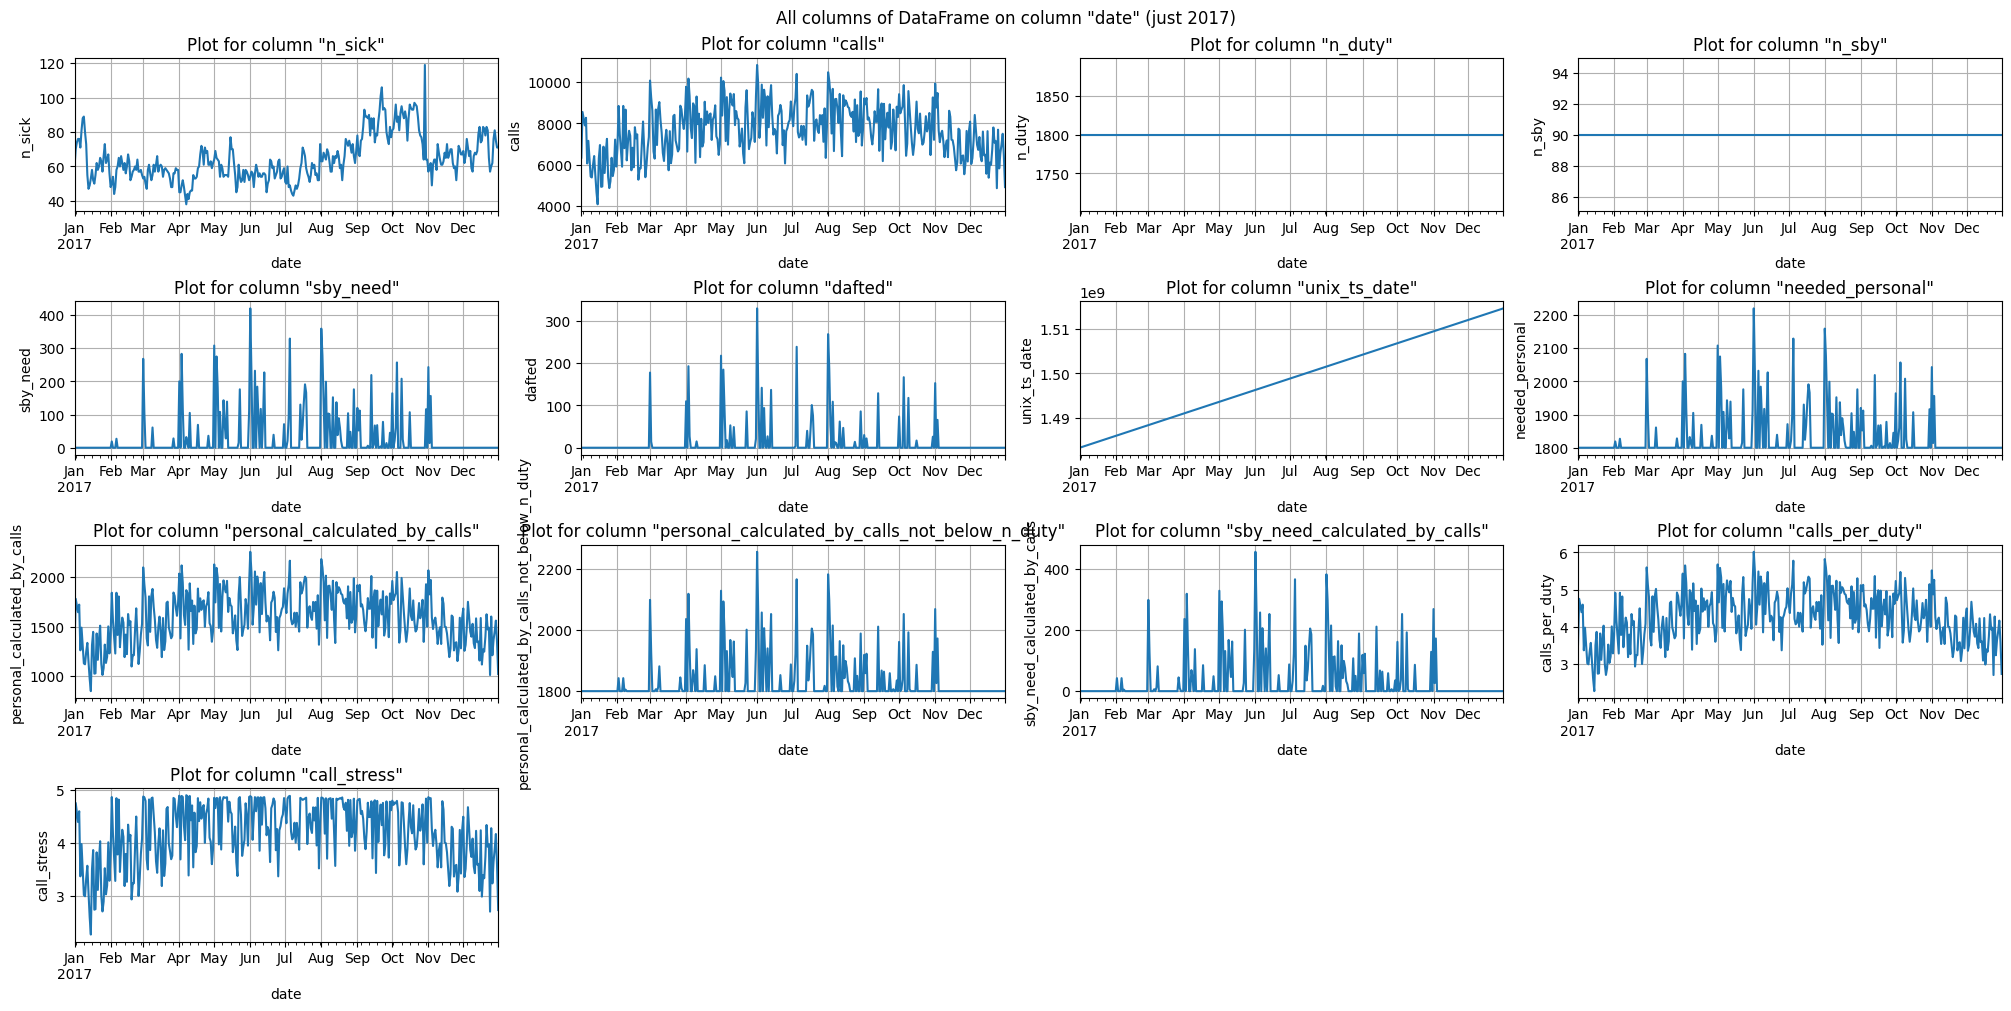

In [90]:
selected_year = 2017

one_year_df = working_df[working_df.index.year == selected_year]

plot_columns_on_index_in_subplots(one_year_df, annotation=f"just {selected_year}")

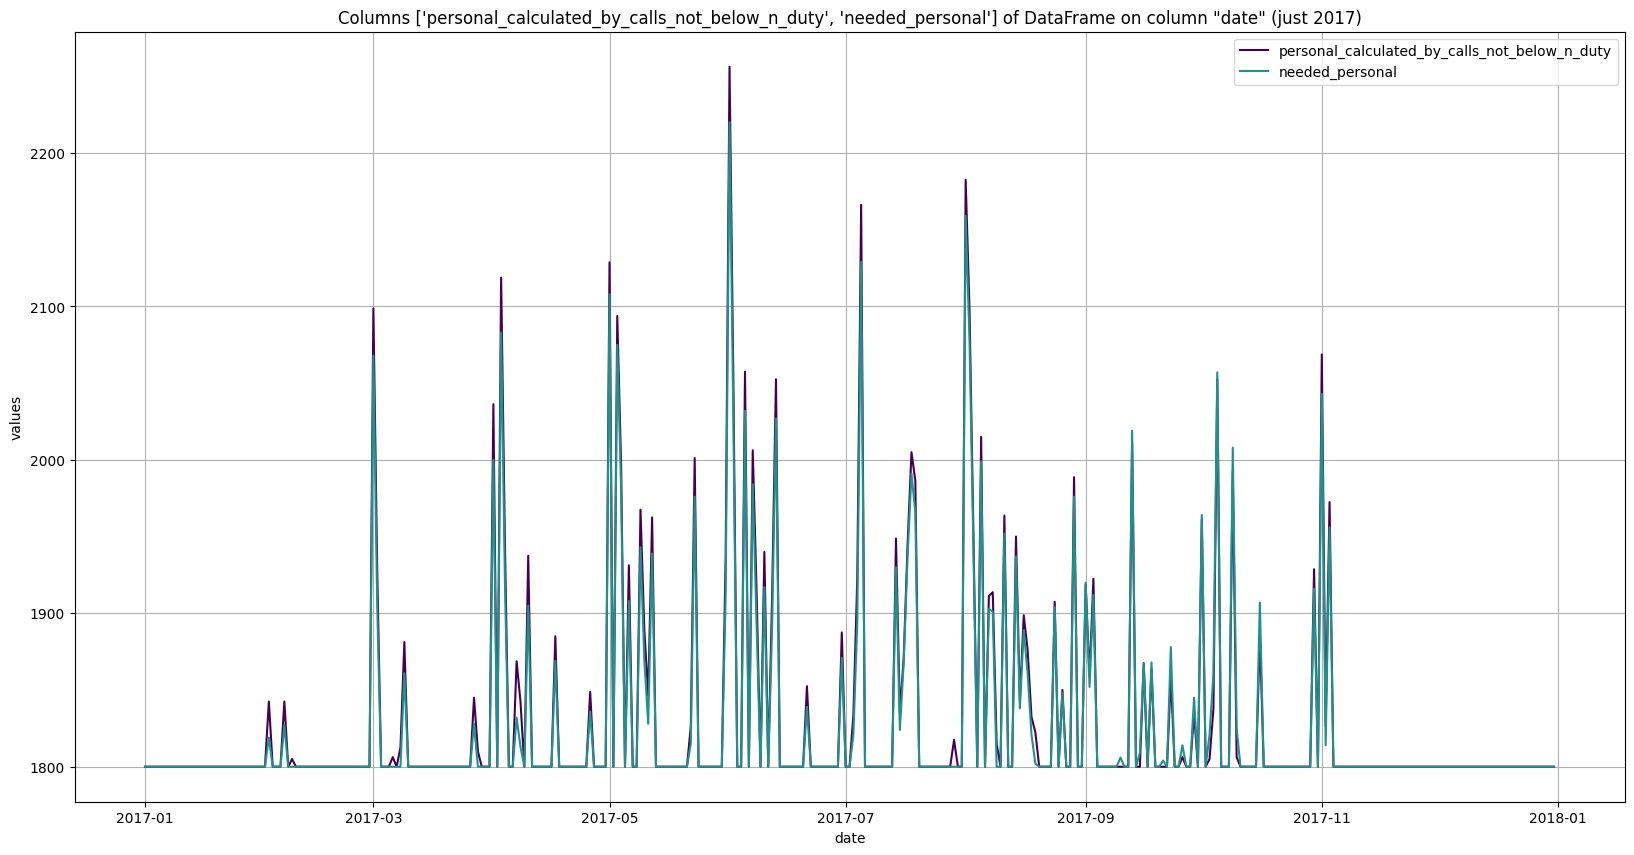

In [91]:
plot_columns_on_index(one_year_df, columns=["personal_calculated_by_calls_not_below_n_duty", "needed_personal"], annotation=f"just {selected_year}")

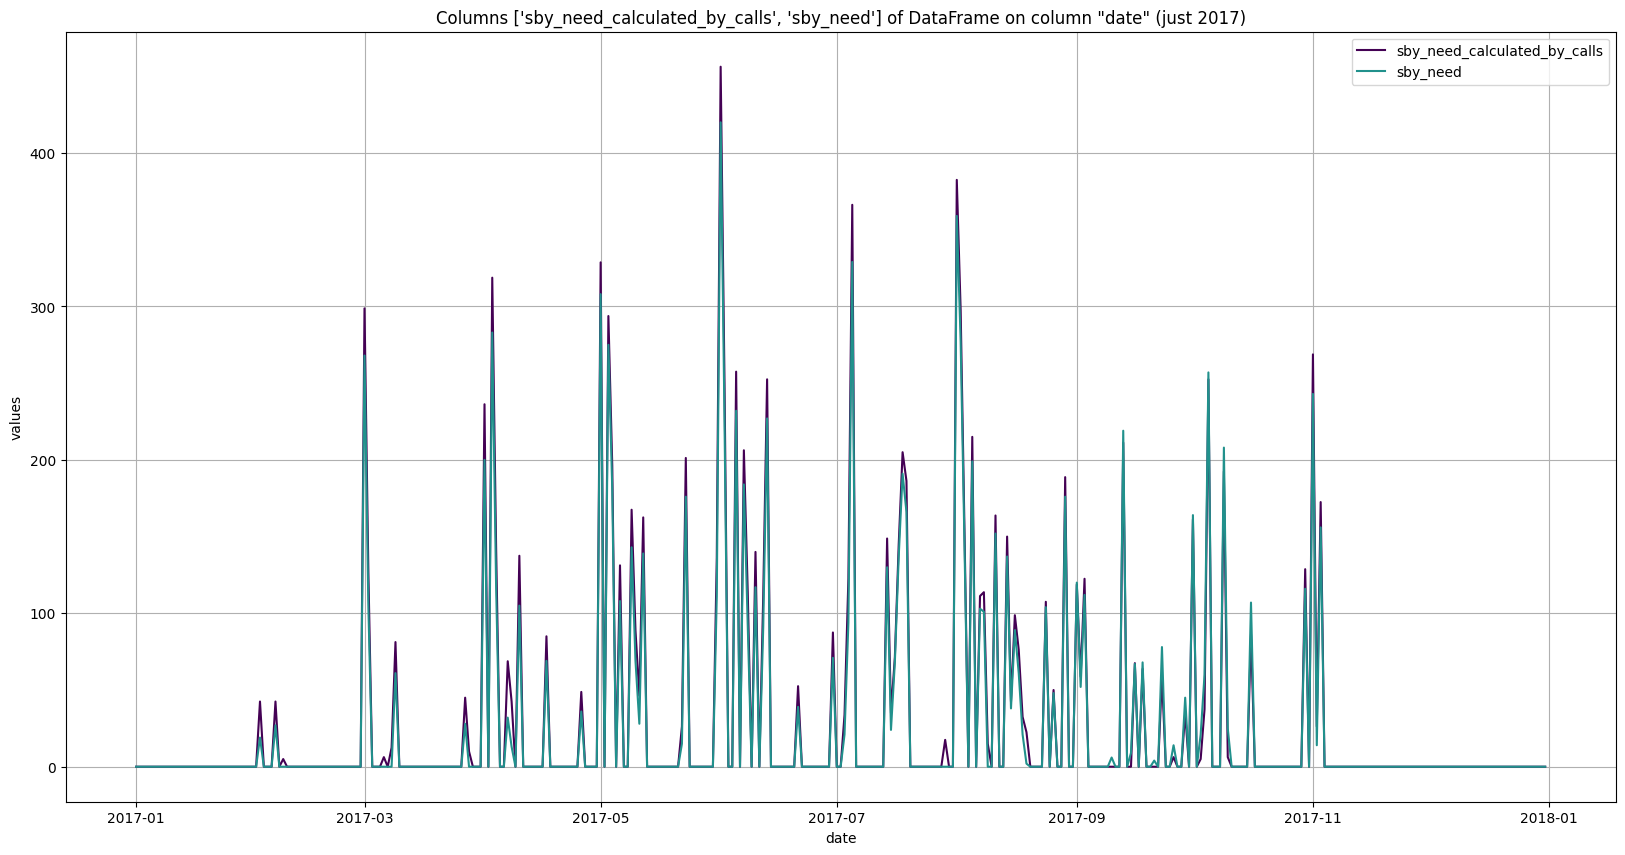

In [92]:
plot_columns_on_index(one_year_df, columns=["sby_need_calculated_by_calls", "sby_need"], annotation=f"just {selected_year}")

## Calculate metrics

In [93]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error


def calculate_regression_metrics(y_test : List, y_pred : List, print_results : bool = False) -> dict:
    results= {
        'MAE': float(mean_absolute_error(y_test, y_pred)),
        'MSE': float(mean_squared_error(y_test, y_pred)),
        'R2':float( r2_score(y_test, y_pred)),
        'MAPE': float(mean_absolute_percentage_error(y_test, y_pred)),
    }

    if print_results:
        print(f'Results: - ' + ', '.join(f'{key}: {value}' for key, value in results.items()))

    return results

print("For needed_personal over all time:")
calculate_regression_metrics(working_df["needed_personal"], working_df["personal_calculated_by_calls_not_below_n_duty"], print_results=True)

print("For sby_need over all time:")
_ = calculate_regression_metrics(working_df["sby_need"], working_df["sby_need_calculated_by_calls"], print_results=True)

For needed_personal over all time:
Results: - MAE: 3.738498263888889, MSE: 72.18950737847223, R2: 0.9948103196819081, MAPE: 0.0019167735471600801
For sby_need over all time:
Results: - MAE: 3.738498263888889, MSE: 72.18950737847223, R2: 0.9886237992741889, MAPE: 576632764789191.1


## Findings

Erkenntnisse:
- das benötigte Personal bzw die Einsatzfahrer im Bereitschaftsdienst kann man problemlos über calls berechnen und das mit einem guten R2-Score

To-Do:
- wie bekommt man calls gut predcitet

# Plot calls

## Plot over years

In [94]:
yearly_df = df.copy(deep=True)

target_column_name = "calls"

range_of_years = range(yearly_df.index.year.min(), yearly_df.index.year.max() + 1)

# New column for each month 
for year in range_of_years:
    yearly_df[f'year_{year}'] = yearly_df.apply(lambda row: row[target_column_name] if row.name.year == year else None, axis=1)

# Only select monthly columns
yearly_df = yearly_df[[f'year_{year}' for year in range_of_years]]

yearly_df.index = yearly_df.index.day_of_year

display(yearly_df)
display(yearly_df.describe())

,year_2016,year_2017,year_2018,year_2019
date,,,,
92,8154.0,NaN,NaN,NaN
93,8526.0,NaN,NaN,NaN
94,8088.0,NaN,NaN,NaN
95,7044.0,NaN,NaN,NaN
96,7236.0,NaN,NaN,NaN
...,...,...,...,...
143,NaN,NaN,NaN,8544.0
144,NaN,NaN,NaN,8814.0
145,NaN,NaN,NaN,9846.0


,year_2016,year_2017,year_2018,year_2019
count,275.000000,365.000000,365.000000,147.000000
mean,7306.472727,7656.953425,8274.032877,8838.163265
std,1124.147688,1229.558677,1147.060667,1286.484080
min,4692.000000,4074.000000,5334.000000,5760.000000
25%,6492.000000,6816.000000,7518.000000,7884.000000
50%,7272.000000,7638.000000,8268.000000,8934.000000
75%,8157.000000,8592.000000,9120.000000,9777.000000
max,10536.000000,10830.000000,11370.000000,11850.000000


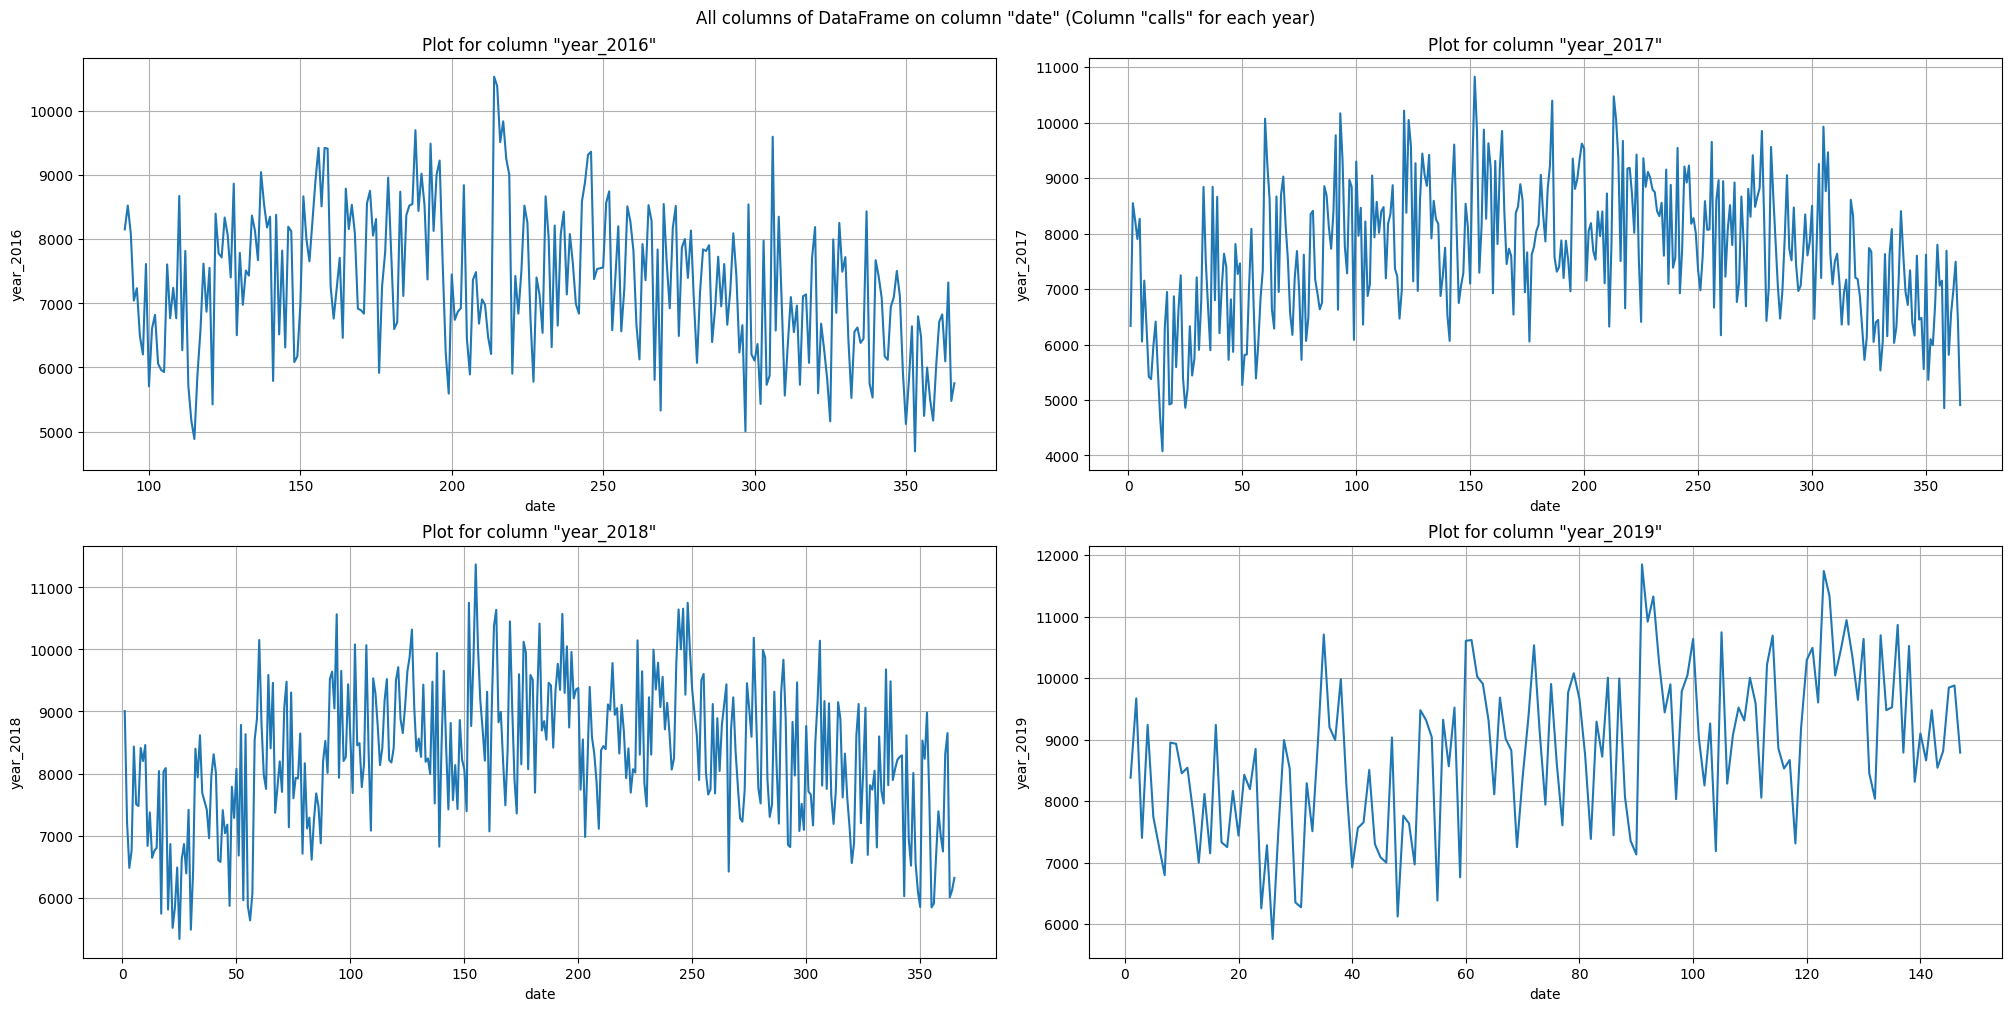

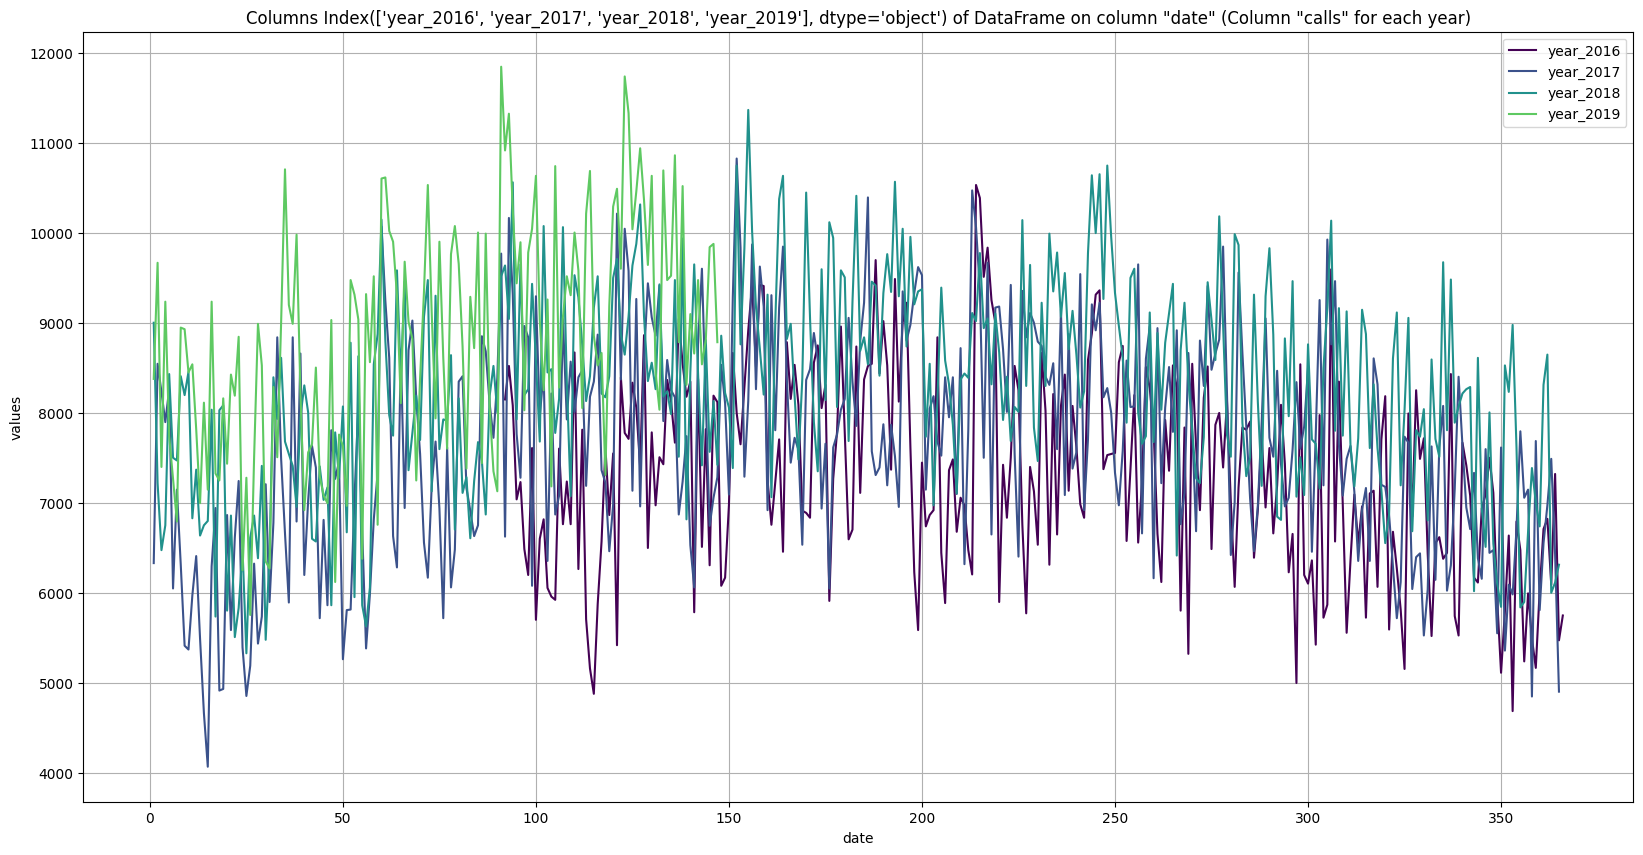

In [95]:
plot_columns_on_index_in_subplots(yearly_df, annotation=f'Column "{target_column_name}" for each year')
plot_columns_on_index(yearly_df, annotation=f'Column "{target_column_name}" for each year')

## Plot over months

In [96]:
selected_year = 2017

monthly_df = df.copy(deep=True)[df.index.year == selected_year]

target_column_name = "calls"


# New column for each month 
for month in range(1, 13):
    monthly_df[f'month_{month}'] = monthly_df.apply(lambda row: row[target_column_name] if row.name.month == month else None, axis=1)

# Only select monthly columns
monthly_df = monthly_df[[f'month_{month}' for month in range(1, 13)]]

monthly_df.index = monthly_df.index.day

display(monthly_df)
display(monthly_df.describe())

,month_1,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
date,,,,,,,,,,,,
1,6336.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,8550.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,8238.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7902.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,8268.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
27,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6558.0
28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6978.0
29,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7494.0


,month_1,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
count,31.000000,28.000000,31.000000,30.000000,31.000000,30.000000,31.000000,31.000000,30.00000,31.000000,30.000000,31.000000
mean,6185.806452,6910.928571,7625.612903,8007.400000,8228.129032,8316.000000,8172.193548,8491.161290,8072.40000,7942.451613,7186.600000,6703.354839
std,1122.510562,998.717916,1090.230363,1048.536734,1112.122887,1098.626729,929.351366,1026.315062,887.55618,942.898893,1069.598977,891.576190
min,4074.000000,5268.000000,5724.000000,6084.000000,6066.000000,6054.000000,6324.000000,6408.000000,6168.00000,6426.000000,5532.000000,4854.000000
25%,5409.000000,5970.000000,6696.000000,7203.000000,7191.000000,7630.500000,7527.000000,7584.000000,7399.50000,7131.000000,6360.000000,6129.000000
50%,6054.000000,6819.000000,7620.000000,8100.000000,8256.000000,8214.000000,7956.000000,8748.000000,8127.00000,7854.000000,7149.000000,6714.000000
75%,6909.000000,7471.500000,8514.000000,8776.500000,9168.000000,9145.500000,8805.000000,9180.000000,8773.50000,8583.000000,7647.000000,7416.000000
max,8550.000000,8844.000000,10074.000000,10170.000000,10218.000000,10830.000000,10398.000000,10476.000000,9654.00000,9852.000000,9930.000000,8406.000000


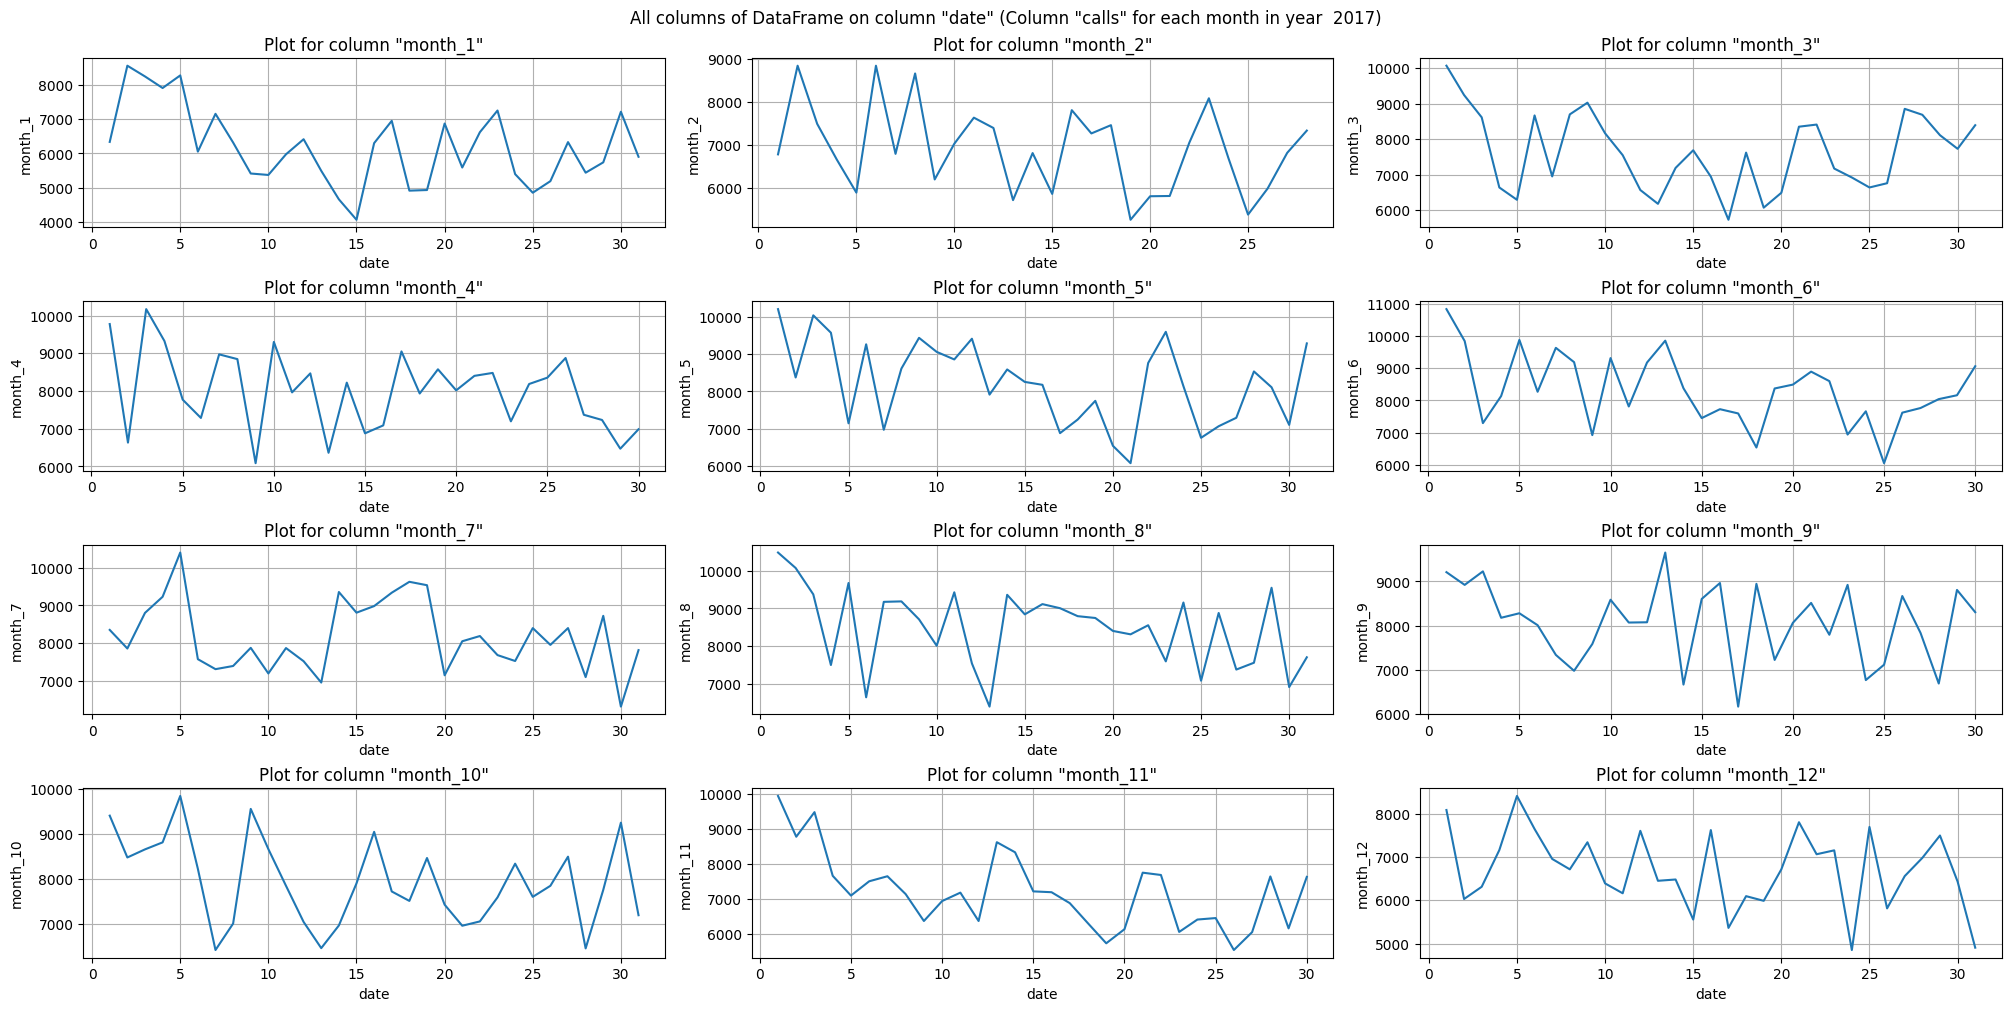

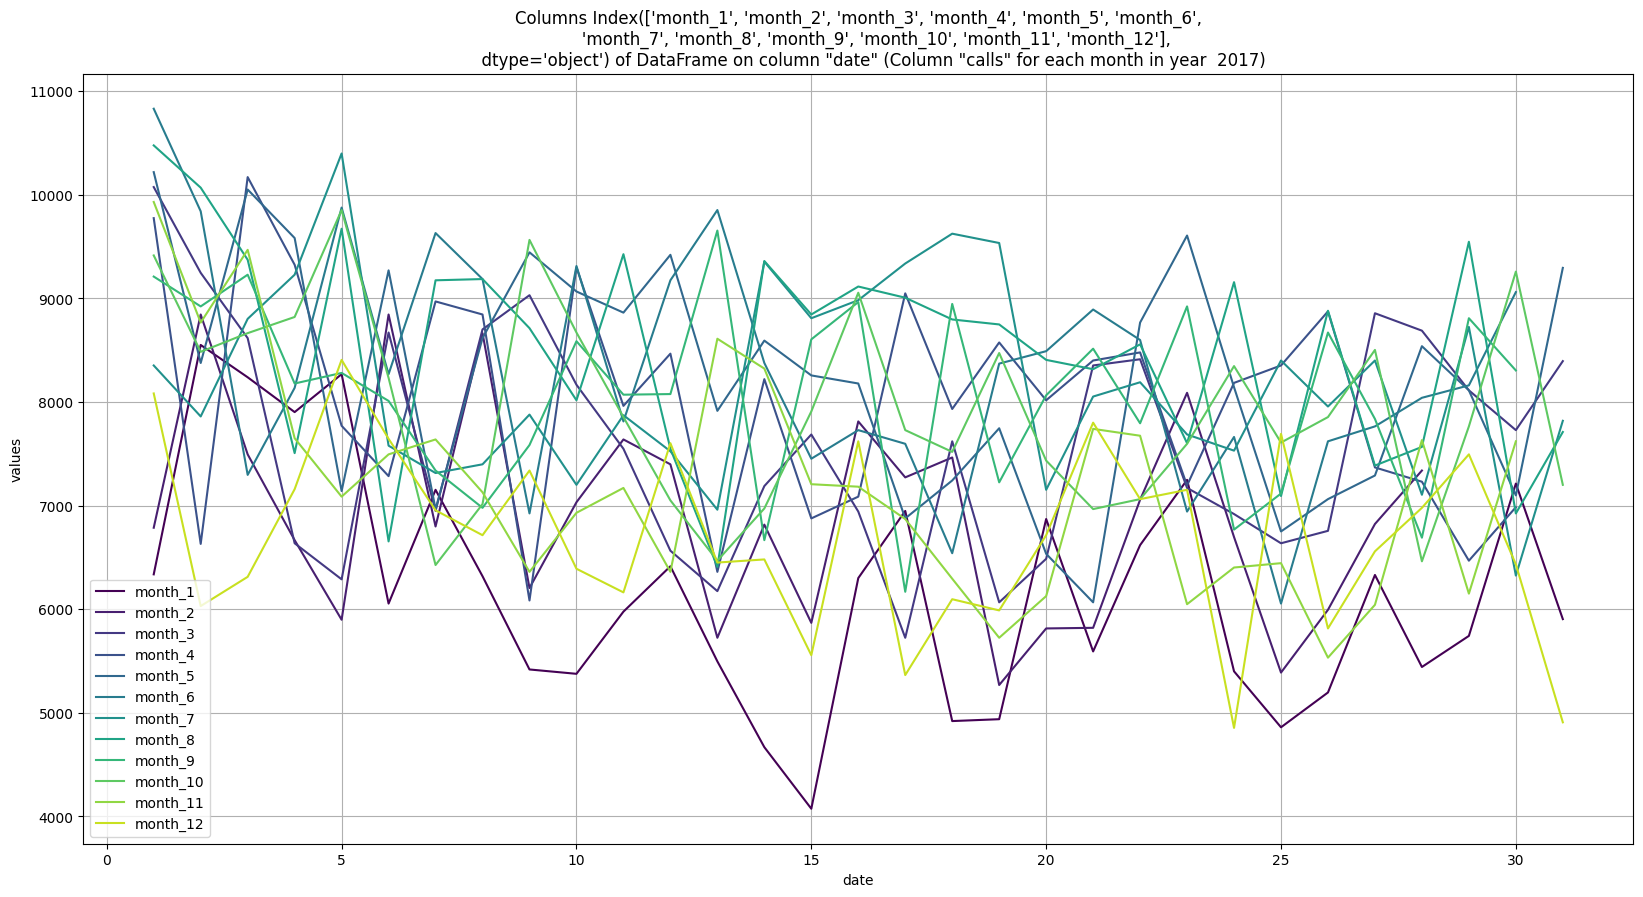

In [97]:
plot_columns_on_index_in_subplots(monthly_df, annotation=f'Column "{target_column_name}" for each month in year  {selected_year}')
plot_columns_on_index(monthly_df, annotation=f'Column "{target_column_name}" for each month in year  {selected_year}')

## Findings

Erkenntnisse: 
- bis auf den Winter wenig Seasonalität bei calls erkennbar

## Plot over weeks

In [98]:
selected_year = 2017

weekly_df = df.copy(deep=True)[df.index.year == selected_year]

target_column_name = "calls"

numer_of_weeks = df.index.isocalendar().week.max()


# New column for each month 
for week in range(1, numer_of_weeks):
    weekly_df[f'week_{week}'] = weekly_df.apply(lambda row: row[target_column_name] if row.name.isocalendar().week == week else None, axis=1)

# Only select monthly columns
weekly_df = weekly_df[[f'week_{week}' for week in range(1, numer_of_weeks)]]

weekly_df.index = weekly_df.index.dayofweek

display(weekly_df)
display(weekly_df.describe())

,week_1,week_2,week_3,week_4,week_5,week_6,week_7,week_8,week_9,week_10,...,week_42,week_43,week_44,week_45,week_46,week_47,week_48,week_49,week_50,week_51
date,,,,,,,,,,,,,,,,,,,,,
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,8550.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,8238.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,7902.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,8268.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,week_1,week_2,week_3,week_4,week_5,week_6,week_7,week_8,week_9,week_10,...,week_42,week_43,week_44,week_45,week_46,week_47,week_48,week_49,week_50,week_51
count,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,...,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000
mean,7497.428571,5346.000000,6026.571429,5745.428571,6972.000000,7511.142857,6603.428571,6408.000000,7860.000000,7946.571429,...,7747.714286,7733.142857,8479.714286,7011.428571,7172.571429,6566.571429,6838.285714,7229.142857,6462.000000,6523.714286
std,1000.638939,779.291986,874.003596,805.884784,1021.175793,964.473506,982.430805,934.132753,1455.656553,946.966887,...,759.805614,662.390476,1157.314379,503.247738,1028.784859,834.545556,896.845902,660.712602,890.456063,966.737075
min,6054.000000,4074.000000,4920.000000,4860.000000,5898.000000,6204.000000,5268.000000,5388.000000,6288.000000,6564.000000,...,6966.000000,6462.000000,7086.000000,6360.000000,5724.000000,5532.000000,6030.000000,6390.000000,5364.000000,4854.000000
25%,6735.000000,5022.000000,5265.000000,5298.000000,6285.000000,6915.000000,5796.000000,5817.000000,6729.000000,7248.000000,...,7248.000000,7602.000000,7425.000000,6645.000000,6582.000000,6087.000000,6096.000000,6834.000000,5859.000000,6042.000000
50%,7902.000000,5418.000000,6300.000000,5442.000000,6786.000000,7398.000000,6816.000000,5994.000000,7338.000000,8166.000000,...,7518.000000,7764.000000,8766.000000,7128.000000,7182.000000,6402.000000,6312.000000,7158.000000,6450.000000,6714.000000
75%,8253.000000,5736.000000,6744.000000,6036.000000,7353.000000,8151.000000,7368.000000,6876.000000,8931.000000,8685.000000,...,8100.000000,8100.000000,9363.000000,7332.000000,7764.000000,7059.000000,7626.000000,7491.000000,7041.000000,7107.000000
max,8550.000000,6414.000000,6948.000000,7248.000000,8844.000000,8844.000000,7812.000000,8088.000000,10074.000000,9030.000000,...,9054.000000,8502.000000,9930.000000,7638.000000,8610.000000,7740.000000,8082.000000,8406.000000,7620.000000,7800.000000


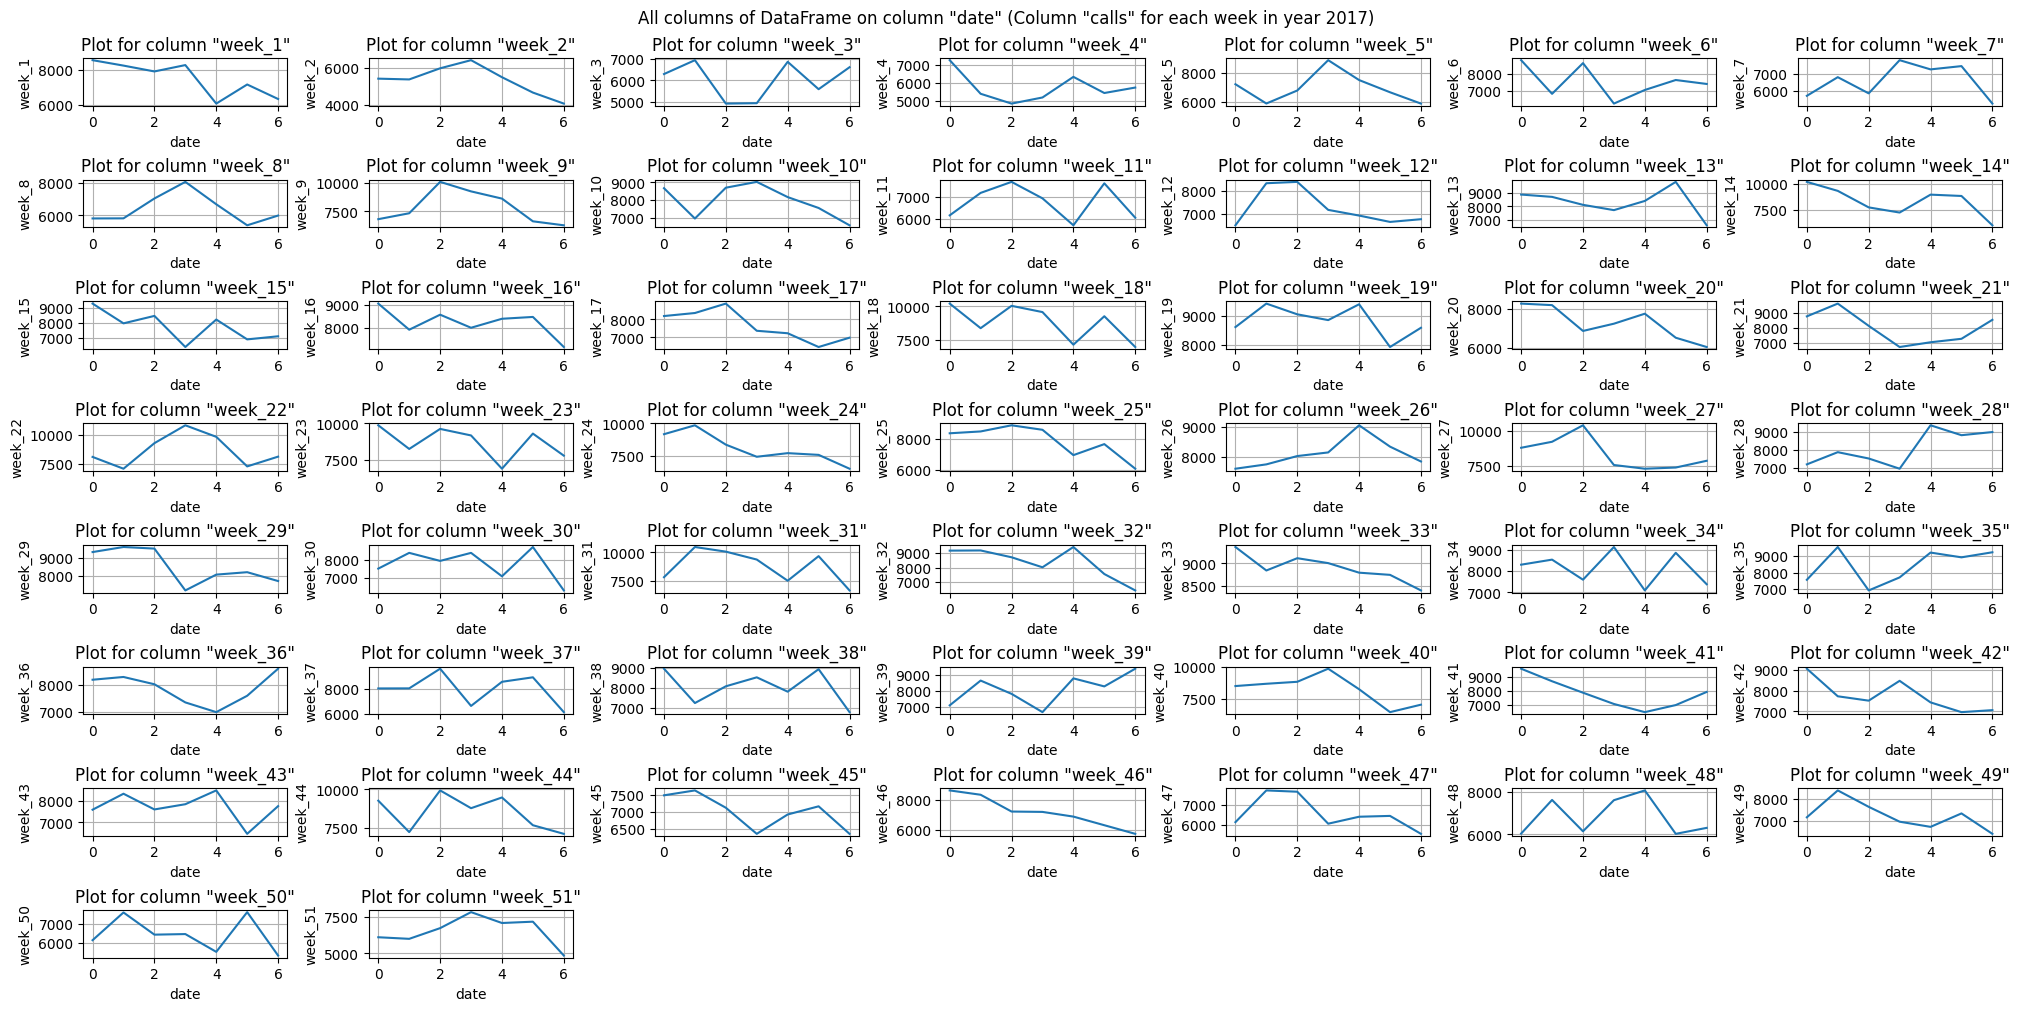

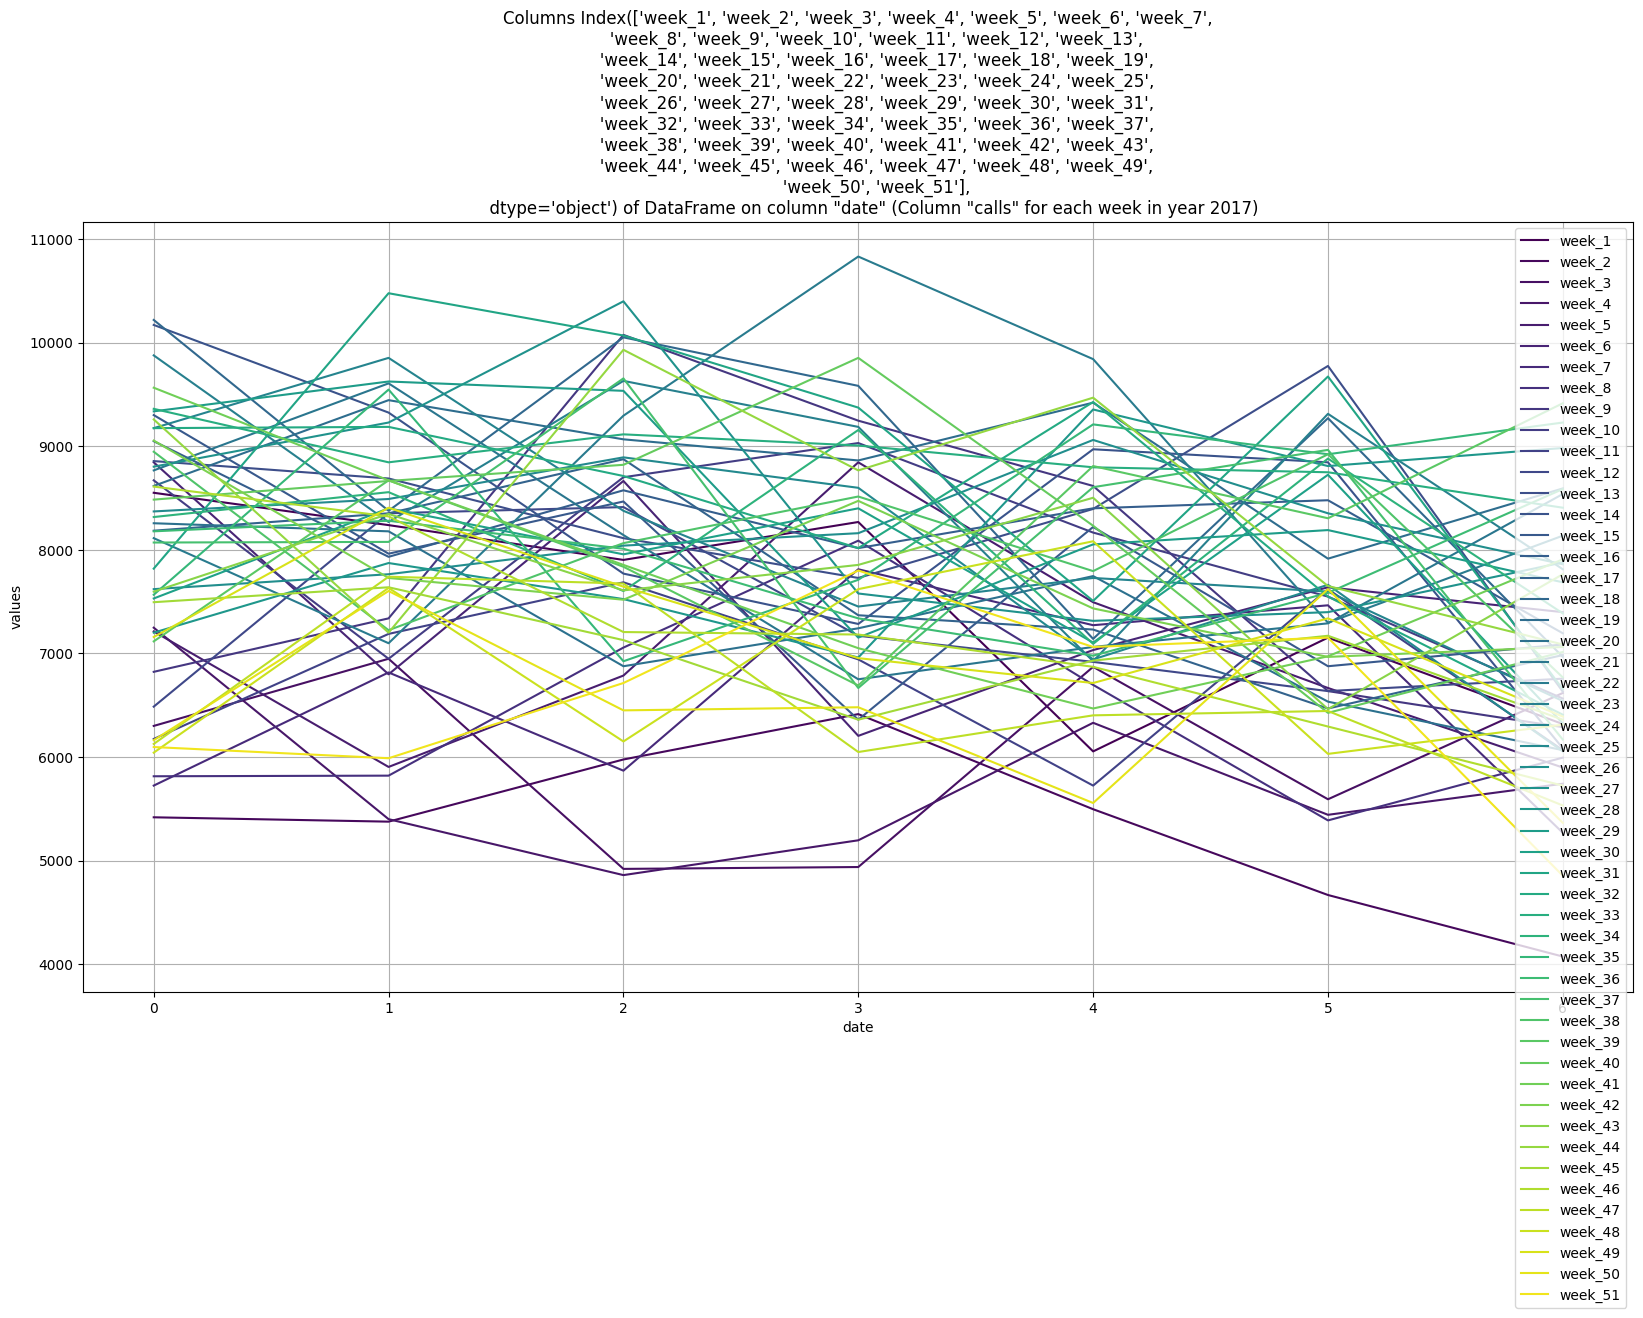

In [99]:
plot_columns_on_index_in_subplots(weekly_df, annotation=f'Column "{target_column_name}" for each week in year {selected_year}')
plot_columns_on_index(weekly_df, annotation=f'Column "{target_column_name}" for each week in year {selected_year}')

# Time series analysis for calls

## SARIMAX

In [223]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error
import matplotlib.pyplot as plt


# Split data in train and test data
train = one_year_df['calls'][:int(len(one_year_df)*0.8)]
test = one_year_df['calls'][int(len(one_year_df)*0.8):]

# ARIMA-Modell 
model = SARIMAX(train, order=(1,1,1), seasonal_order=(1,1,1,12))
model_fit = model.fit(disp=False)

# Prediction
predictions = model_fit.forecast(steps=len(test))


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [304]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error

def plot_regression_predictions(y_true: pd.DataFrame, y_pred: pd.DataFrame, y_train: pd.DataFrame = None, annotation : str = "", additional_column_df : pd.DataFrame = None) -> None:

    plt.figure(figsize=(20, 10))

    # Metrics
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)

    # Plot 
    plt.figure(figsize=(10, 6))
    plt.title(f'Prediction results' + (f" ({annotation})" if annotation else ""))

    if y_train is not None:
        plt.plot(y_train.index, y_train, label='Train', color='blue')

    plt.plot(y_true.index, y_true, label='Test', color='green')
    plt.plot(y_true.index, y_pred, label='Predictions', color='red')

    if additional_column_df is not None:

        for column in additional_column_df.columns:
            plt.plot(additional_column_df.index, additional_column_df[column], label= "+ " + column)

    props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)

    textstr = '\n'.join((
        r'$R^2=%.2f$' % (r2, ),
        r'$MAE=%.2f$' % (mae, ),
        r'$MAPE=%.2f$' % (mape, )))

    plt.text(0.8, 0.2, textstr, transform=plt.gca().transAxes, fontsize=14,
        verticalalignment='top', bbox=props)

    plt.legend()
    plt.grid()
    plt.show()

plot_regression_predictions(test, predictions, y_train=train, annotation="For SARIMAX")

ValueError: Found input variables with inconsistent numbers of samples: [73, 337]

<Figure size 2000x1000 with 0 Axes>

## LSTM (Long Short-Term Memory)

Epoch 1/10


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 0.7258 - val_loss: 0.0576
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0537 - val_loss: 0.0572
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0623 - val_loss: 0.0581
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0632 - val_loss: 0.0550
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0701 - val_loss: 0.0874
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0739 - val_loss: 0.0649
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0616 - val_loss: 0.0549
Epoch 8/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0614 - val_loss: 0.0646
Epoch 9/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0642 - val_loss: 0.1143
Epoch 10/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0764 - val_loss: 0.0527


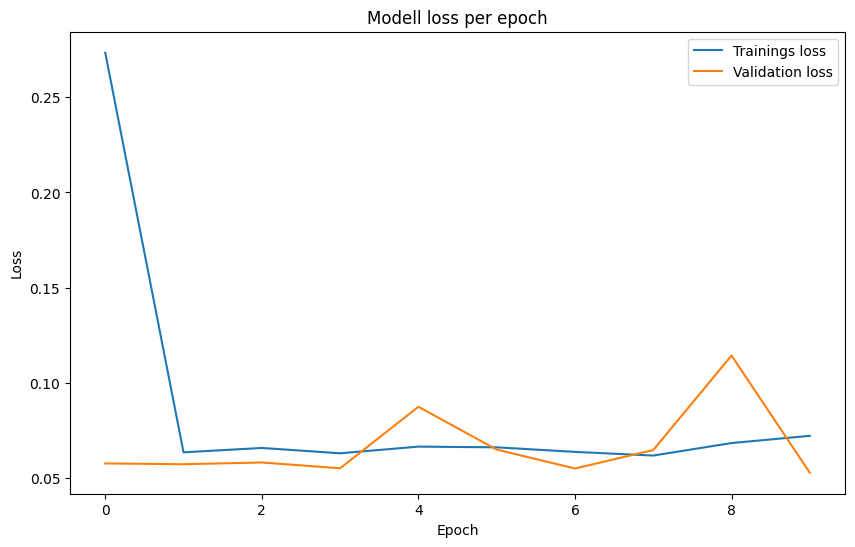

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step


In [287]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from keras.models import Sequential
from keras.layers import LSTM, Dense, Bidirectional, Dropout
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.optimizers import Adam

target_column_name = "calls"

data = df[[target_column_name]]

# Indizes speichern
indices = data.index

# Daten normalisieren
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# Sequenzen erstellen
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 30  # Anzahl der Tage in einer Sequenz
X, y = create_sequences(scaled_data, seq_length)

# Daten in Trainings- und Testsets aufteilen
split = int(0.7 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# LSTM-Modell erstellen
model = Sequential()

# V1 LSTM
#model.add(LSTM(units=50, return_sequences=True, input_shape=(seq_length, 1)))
#model.add(LSTM(units=50))

# V2 LSTM
model.add(Bidirectional(LSTM(units=100, return_sequences=True, input_shape=(seq_length, 1))))
model.add(Dropout(0.2))
model.add(Bidirectional(LSTM(units=100)))
model.add(Dropout(0.2))
######

model.add(Dense(1))

# V1 Modell kompilieren
#model.compile(optimizer='adam', loss='mean_squared_error')

# Asymmetrische Verlustfunktion definieren
def custom_loss(y_true, y_pred):
    loss = tf.where(tf.greater(y_true, y_pred), 
                    tf.square(y_true - y_pred) * 20,  # Straffaktor für Unterschätzungen
                    tf.square(y_true - y_pred))
    return tf.reduce_mean(loss)

# V2 Modell kompilieren
# model.compile(optimizer='adam', loss=custom_loss)

# V3 Modell kompilieren
model.compile(optimizer=Adam(learning_rate=0.001), loss=custom_loss)

# Modell trainieren
history = model.fit(X_train, y_train, epochs=10, batch_size=16, validation_split=0.2)

plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Trainings loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Modell loss per epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Vorhersagen machen
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)

y_test = scaler.inverse_transform(y_test)
y_train = scaler.inverse_transform(y_train)

# Indizes wieder hinzufügen
y_test = pd.DataFrame(y_test, index=indices[-len(y_test):])
predictions = pd.DataFrame(predictions, index=indices[-len(predictions):])
y_train = pd.DataFrame(y_train, index=indices[:len(y_train)])


# Highest R2-Score: 27%

<Figure size 2000x1000 with 0 Axes>

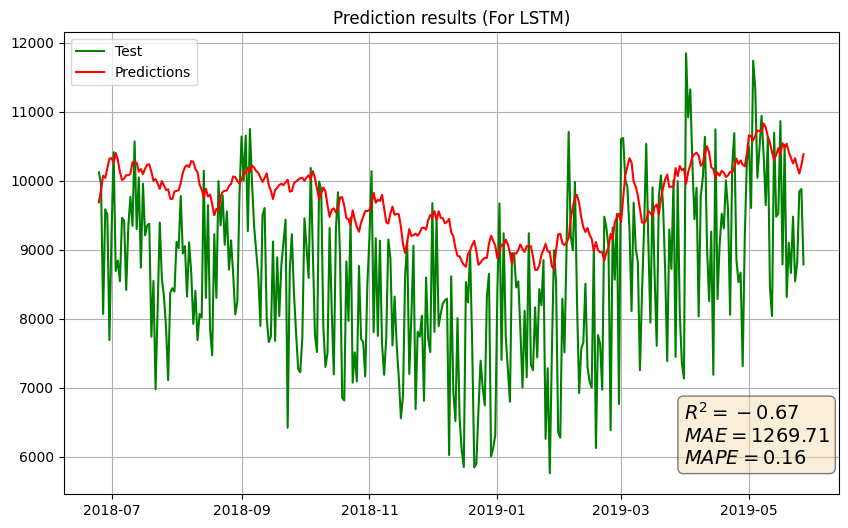

<Figure size 2000x1000 with 0 Axes>

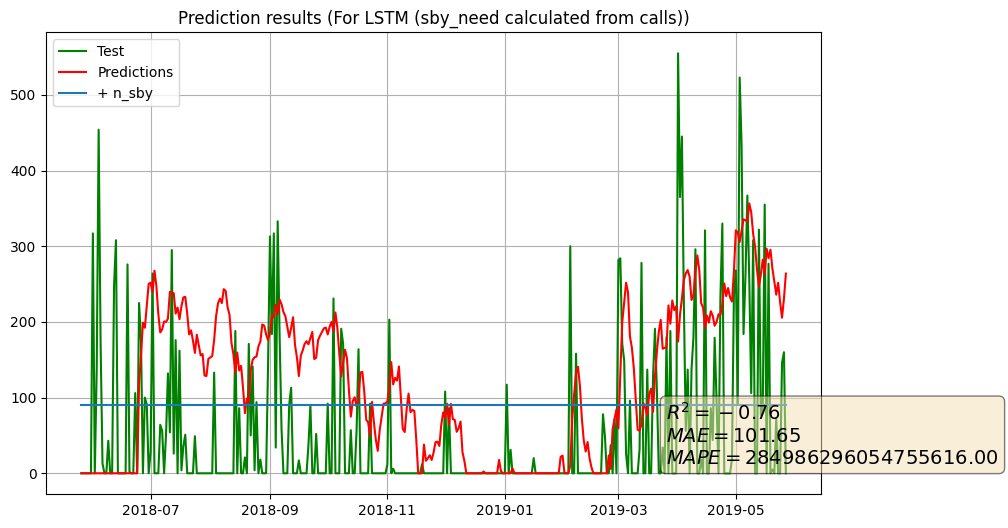

In [306]:
plot_regression_predictions(y_test, predictions, annotation="For LSTM")

if target_column_name == "calls":

    result_df = df[split:][["n_duty", "sby_need", "n_sby"]]
    result_df["predicted_calls"] = predictions
    result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.8) - row.n_duty) , axis=1)

    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]], annotation="For LSTM (sby_need calculated from calls)")

## GRU (Gated Recurrent Unit)

In [276]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from keras.models import Sequential
from keras.layers import GRU, Dense, Dropout, Bidirectional
import matplotlib.pyplot as plt
import tensorflow as tf


target_column_name = "calls"

data = df[[target_column_name]]

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 30
X, y = create_sequences(scaled_data, seq_length)
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# GRU-Modell erstellen
model = Sequential()
model.add(Bidirectional(GRU(units=200, return_sequences=True, input_shape=(seq_length, 1))))
model.add(Dropout(0.3))
model.add(Bidirectional(GRU(units=200)))
model.add(Dropout(0.3))
model.add(Dense(1))

# Asymmetrische Verlustfunktion definieren
def custom_loss(y_true, y_pred):
    loss = tf.where(tf.greater(y_true, y_pred), 
                    tf.square(y_true - y_pred) * 1.5,  # Straffaktor für Unterschätzungen erhöhen
                    tf.square(y_true - y_pred))
    return tf.reduce_mean(loss)

# Modell kompilieren
model.compile(optimizer='adam', loss=custom_loss)

# Modell trainieren
history = model.fit(X_train, y_train, epochs=100, batch_size=16, validation_split=0.2)

# Plot der Trainings- und Validierungsverluste pro Epoche
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Trainingsverlust')
plt.plot(history.history['val_loss'], label='Validierungsverlust')
plt.title('Modellverlust pro Epoche')
plt.xlabel('Epoche')
plt.ylabel('Verlust')
plt.legend()
plt.show()

# Vorhersagen machen
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)

y_test = scaler.inverse_transform(y_test)
y_train = scaler.inverse_transform(y_train)

# Indizes wieder hinzufügen
y_test = pd.DataFrame(y_test, index=indices[-len(y_test):])
predictions = pd.DataFrame(predictions, index=indices[-len(predictions):])
y_train = pd.DataFrame(y_train, index=indices[:len(y_train)])

Epoch 1/100


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 56ms/step - loss: 0.0236 - val_loss: 0.0404
Epoch 2/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.0148 - val_loss: 0.0353
Epoch 3/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 0.0158 - val_loss: 0.0361
Epoch 4/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.0148 - val_loss: 0.0317
Epoch 5/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.0194 - val_loss: 0.0345
Epoch 6/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.0177 - val_loss: 0.0321
Epoch 7/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.0161 - val_loss: 0.0324
Epoch 8/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 0.0202 - val_loss: 0.0331
Epoch 9/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 0.0167 - val_loss: 0.0331
Epoch 10/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 0.0171 - val_loss: 0.0348
Epoch 11/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 0.0223 - val_loss: 0.0324
Epoch 12/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 0.0

KeyboardInterrupt: 

<Figure size 2000x1000 with 0 Axes>

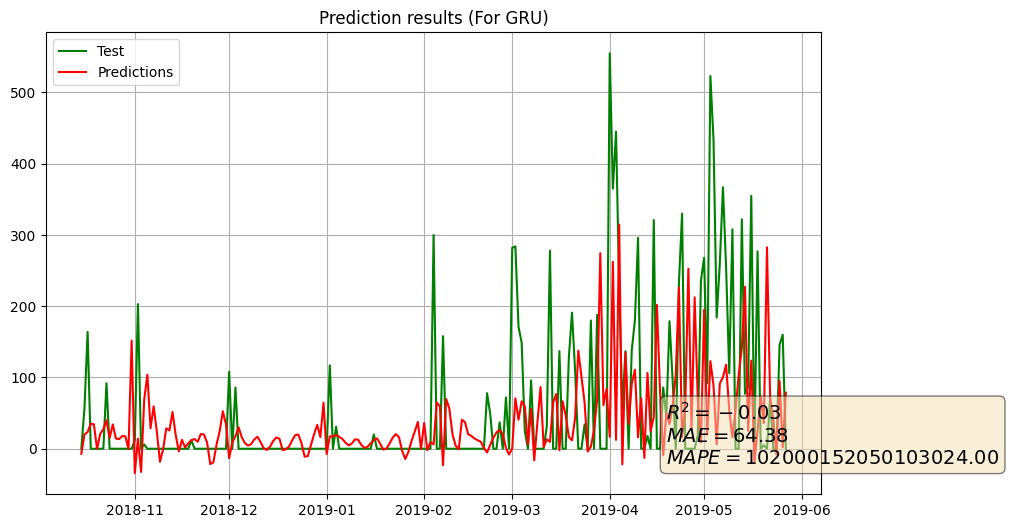

In [ ]:
plot_regression_predictions(y_test, predictions, y_train=y_train, annotation="For GRU")

if target_column_name == "calls":

    result_df = df[split:][["n_duty", "sby_need"]]
    result_df["predicted_calls"] = predictions
    result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.8) - row.n_duty) , axis=1)

    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], annotation="For GRU (sby_need calculated from calls)")

## CNN (Convolutional Neural Networks)

Epoch 1/300


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0290 - val_loss: 0.0344
Epoch 2/300
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0206 - val_loss: 0.0365
Epoch 3/300
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0169 - val_loss: 0.0361
Epoch 4/300
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0163 - val_loss: 0.0353
Epoch 5/300
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0169 - val_loss: 0.0353
Epoch 6/300
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0214 - val_loss: 0.0347
Epoch 7/300
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0165 - val_loss: 0.0351
Epoch 8/300
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0138 - val_loss: 0.0351
Epoch 9/300
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0203 - val_loss: 0.0349
Epoch 10/300
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0158 - val_loss: 0.0358
Epoch 11/300
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0160 - val_loss: 0.0354
Epoch 12/300
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0158 - val_lo

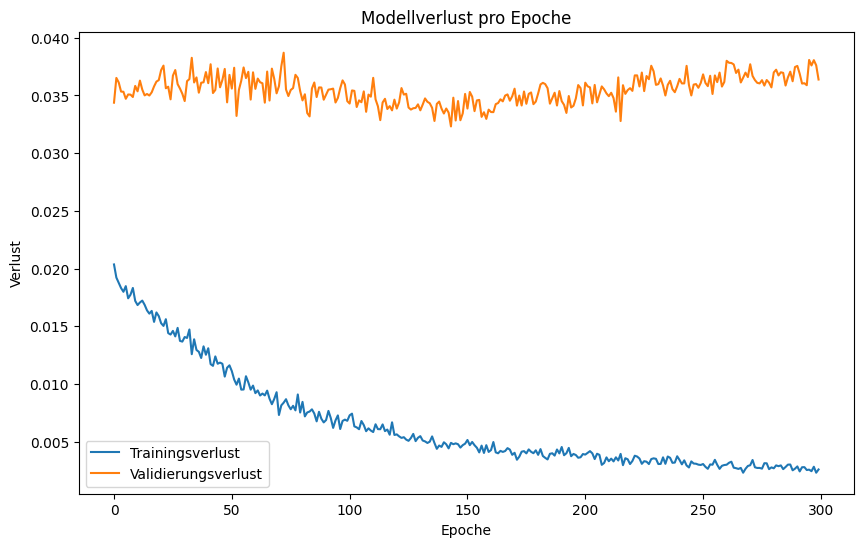

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


In [213]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
import matplotlib.pyplot as plt
import tensorflow as tf

target_column_name = "calls"

data = df[[target_column_name]]

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 30
X, y = create_sequences(scaled_data, seq_length)
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# CNN-Modell erstellen
model = Sequential()
model.add(Conv1D(filters=64, kernel_size=2, activation='relu', input_shape=(seq_length, 1)))
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.3))
model.add(Conv1D(filters=64, kernel_size=2, activation='relu'))
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.3))
model.add(Flatten())
model.add(Dense(50, activation='relu'))
model.add(Dense(1))

# Asymmetrische Verlustfunktion definieren
def custom_loss(y_true, y_pred):
    loss = tf.where(tf.greater(y_true, y_pred), 
                    tf.square(y_true - y_pred) * 1.5,  # Straffaktor für Unterschätzungen erhöhen
                    tf.square(y_true - y_pred))
    return tf.reduce_mean(loss)

# Modell kompilieren
model.compile(optimizer='adam', loss=custom_loss)

# Modell trainieren
history = model.fit(X_train, y_train, epochs=300, batch_size=16, validation_split=0.2)

# Plot der Trainings- und Validierungsverluste pro Epoche
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Trainingsverlust')
plt.plot(history.history['val_loss'], label='Validierungsverlust')
plt.title('Modellverlust pro Epoche')
plt.xlabel('Epoche')
plt.ylabel('Verlust')
plt.legend()
plt.show()

# Vorhersagen machen
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)

y_test = scaler.inverse_transform(y_test)
y_train = scaler.inverse_transform(y_train)

# Indizes wieder hinzufügen
y_test = pd.DataFrame(y_test, index=indices[-len(y_test):])
predictions = pd.DataFrame(predictions, index=indices[-len(predictions):])
y_train = pd.DataFrame(y_train, index=indices[:len(y_train)])

<Figure size 2000x1000 with 0 Axes>

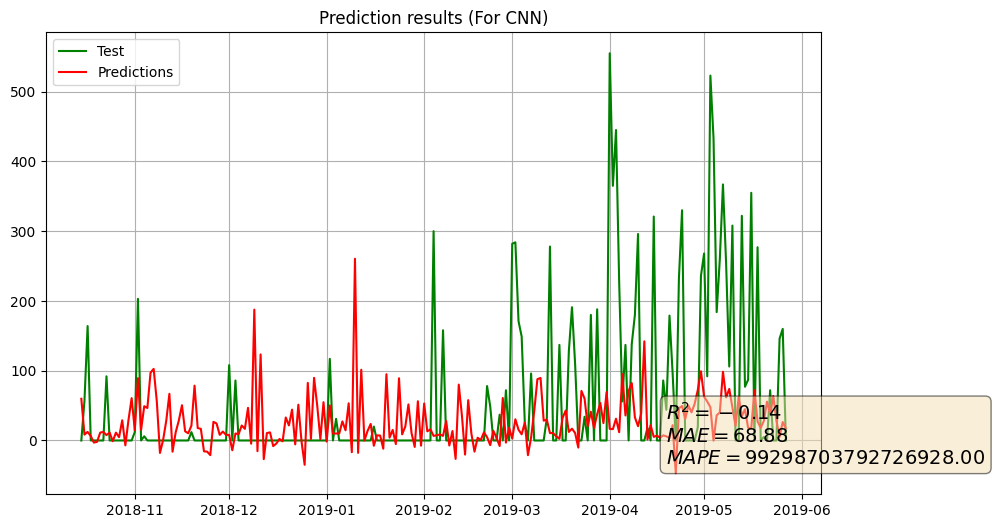

In [215]:
plot_regression_predictions(y_test, predictions, annotation="For CNN")

if target_column_name == "calls":

    result_df = df[split:][["n_duty", "sby_need"]]
    result_df["predicted_calls"] = predictions
    result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.8) - row.n_duty) , axis=1)

    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], annotation="For CNN (sby_need calculated from calls)")